In [1]:
# This is the main code for constructing the disordered circuits models reported in Simon et al. 

# The code below should be run after performing CPM on a series of symptom measures/items. 
# It requires the connectivity matrices, the CPM prediction strengths and derived network masks for each symptom, and the symptom scores as input data.

# The steps are as follows:
# 1. Examine the shared and unique network space and identify how often edges are represented in symptom networks
# 2. Characterize intersubject network heterogeneity (i.e., are there differences in the edges that are dysfunctional between individuals?)
# 3. Construct disordered circuit models
# 4. Examine how diagnostic specificity and comorbidity relates to features within disordered circuit models

In [1]:
import seaborn as sns
import numpy as np

import pandas as pd
from numpy import corrcoef
from statsmodels.stats.multitest import multipletests, fdrcorrection

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib import colors
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.colorbar as cbar
from matplotlib.patches import Wedge, Patch

import scipy.io as sio
from scipy import stats
from scipy.stats import spearmanr, pearsonr, rankdata, norm, hypergeom, ttest_ind, kurtosis, skew, zscore, linregress
from scipy.spatial.distance import squareform, pdist
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, leaves_list, to_tree
from scipy.interpolate import make_interp_spline

from pathlib import Path

from sklearn import preprocessing
from sklearn import cluster
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

import statsmodels.api as sm

import os

import networkx as nx
from networkx.algorithms.community import louvain_communities

from upsetplot import UpSet, from_indicators

In [2]:
# Load connectomes
connectomes_file = '/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Input_data/averaged_mats.mat'
connectomes = sio.loadmat(connectomes_file)['avg_mats']

# Unfold matrices so that they're 35778 x 317
vectors = np.zeros((35778,317))

for s in range(connectomes.shape[2]):
    vectors[:,s] = connectomes[:,:,s][np.triu_indices(268, k=1)]
    
vectors_z = zscore(vectors, axis=1, ddof=0, nan_policy='omit')

In [3]:
# Load raw BSI data
BSIdata_raw = '/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Input_data/BSI_items.xlsx'
BSI_raw_df = pd.read_excel(BSIdata_raw)

BSI_raw = BSI_raw_df.to_numpy()

In [4]:
# Load BSI item info
BSI_info = '/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Input_data/BSI items headers.xlsx'
BSI_info_df = pd.read_excel(BSI_info,header=None)
BSI_info = BSI_info_df.to_numpy()

BSI_item_labels = BSI_info[:,0]
BSI_item_categories = BSI_info[:,1]

# Sort items based on their categories (e.g., put all depression items together)
BSI_order = np.argsort(BSI_item_categories)

cats_sorted = BSI_item_categories[BSI_order]
labels_sorted = BSI_item_labels[BSI_order]

In [5]:
# Load BSI item predictions data
BSI_preds = sio.loadmat('/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Prediction_data/BSI_item_predictions.mat')['r_preds']
BSI_preds_sorted = BSI_preds[:,BSI_order]

BSI_pvals = sio.loadmat('/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Prediction_data/BSI_item_predictions.mat')['p_values'].squeeze()
BSI_pvals_sorted = BSI_pvals[BSI_order]

BSI_networks_pos = sio.loadmat('/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Prediction_data/BSI_item_predictions.mat')['nets_pos']
BSI_networks_pos_sorted = BSI_networks_pos[:,BSI_order]

BSI_networks_neg = sio.loadmat('/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Prediction_data/BSI_item_predictions.mat')['nets_neg']
BSI_networks_neg_sorted = BSI_networks_neg[:,BSI_order]

BSI_networks = sio.loadmat('/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Prediction_data/BSI_item_predictions.mat')['nets_both']
BSI_networks_sorted = BSI_networks[:,BSI_order]

BSI_raw_sorted = BSI_raw[:,BSI_order]

# Correct predictions p-values for multiple comparisons
alpha = 0.05  # FDR level
issig, BSI_pvals_fdr = fdrcorrection(BSI_pvals_sorted, alpha=alpha, method='indep')

labels_sorted_sig = labels_sorted[issig]

BSI_preds_sorted_sig = BSI_preds_sorted[:,issig]

In [6]:
BSI_labels_plot = ['Guilt', 'Trouble falling asleep', 'Fear',
       'Anxiety 1', 'Anxiety 2', 'Anxiety 3', 'Depression 1',
       'Depression 2', 'Depression 3',
       'Hostility 1','Hostility 2',
       'Interpersonal sensitivity 1',
       'Interpersonal sensitivity 2', 'Interpersonal sensitivity 3',
       'Paranoid ideation 1', 'Paranoid ideation 2', 'Paranoid ideation 3',
       'Phobic anxiety',
       'Psychoticism',
       'Somatization 1', 'Somatization 2',
       'Somatization 3', 'Somatization 4',
       'Somatization 5']

In [7]:
# Load MINI data
minipath = "/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Input_data/MINI_toUse_binary.xlsx"

mini_df = pd.read_excel(minipath)
mini_header = mini_df.columns.to_list()
mini_data = mini_df.to_numpy()

# Show symptoms we can predict, network similarity, and shared/unique features

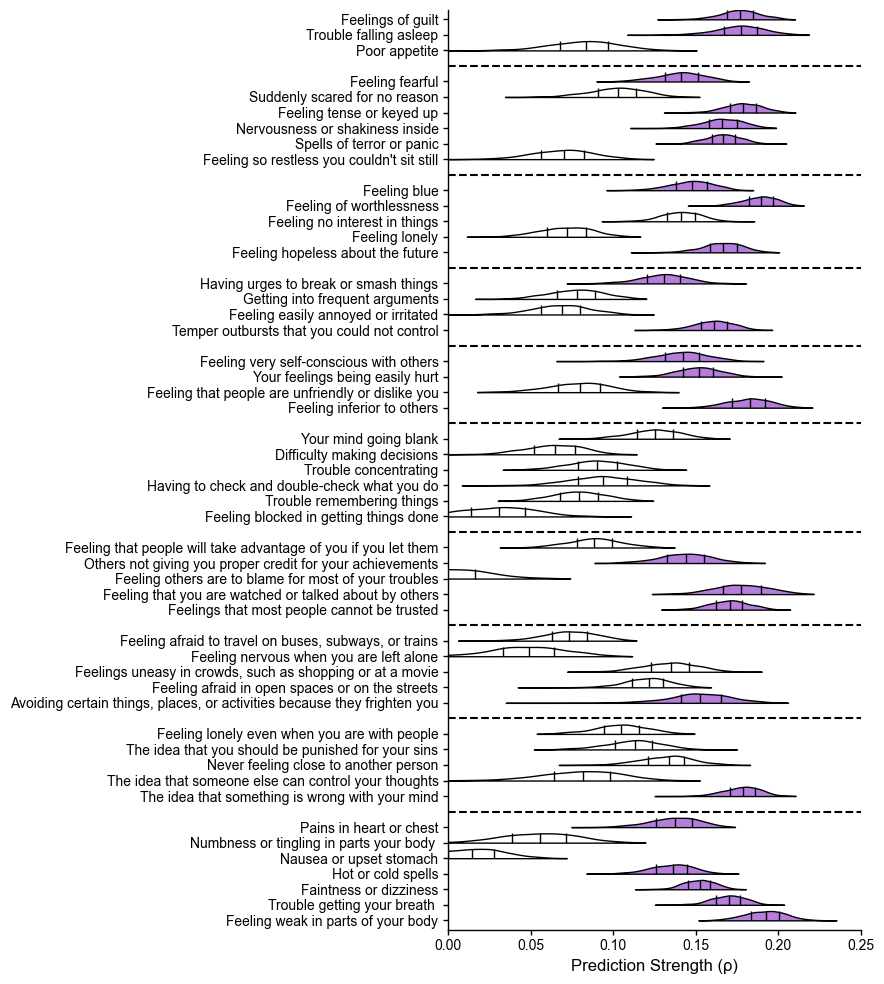

In [8]:
################### Plot all predictions for supplemental figure 1

BSI_preds_sorted_plot = []
BSI_pvals_fdr_plot = []
labels_plot = []
positions = []
gap_positions = []

pos = 1
last_cat = cats_sorted[0]

for i in range(len(BSI_pvals_fdr)):

    # Store data for this item
    positions.append(pos)
    BSI_preds_sorted_plot.append(BSI_preds_sorted[:, i])
    BSI_pvals_fdr_plot.append(BSI_pvals_fdr[i])
    labels_plot.append(labels_sorted[i])

    # Add an extra plotting space when the category changes
    if (
        i < len(BSI_pvals_fdr) - 1
        and cats_sorted[i + 1] != last_cat
    ):
        pos += 2
        gap_positions.append(pos - 1)
        last_cat = cats_sorted[i + 1]
    else:
        pos += 1

# Remove NaNs (if any)
BSI_preds_sorted_plot = [
    np.asarray(values)[np.isfinite(values)]
    for values in BSI_preds_sorted_plot
]

BSI_pvals_fdr_plot = np.asarray(BSI_pvals_fdr_plot)


################### Plot ######################

plt.figure(figsize=(9, 10), facecolor='white')

ax = plt.gca()
ax.set_facecolor('white')

vp = ax.violinplot(
    dataset=BSI_preds_sorted_plot,
    positions=positions,
    vert=False,
    widths=1.2,
    showmeans=False,
    showmedians=False,
    showextrema=False
)


#################### Convert to half violins ###################
for body, center_position, pval in zip(
    vp['bodies'],
    positions,
    BSI_pvals_fdr_plot
):

    if pval < 0.05:
        body.set_facecolor('#B57EDC')  # significant
    else:
        body.set_facecolor('white')    # non-significant

    body.set_edgecolor('black')
    body.set_linewidth(1)
    body.set_alpha(1)

    path = body.get_paths()[0]
    vertices = path.vertices

    # Keep the lower half and collapse the upper half
    vertices[vertices[:, 1] > center_position, 1] = center_position

#################### Add quartile and median lines ###################
half_violin_width = 1.2 / 2

for values, center_position in zip(
    BSI_preds_sorted_plot,
    positions
):

    q25, median, q75 = np.percentile(
        values,
        [25, 50, 75]
    )

    # Quartile lines extending through the retained half
    ax.vlines(
        x=[q25, median, q75],
        ymin=center_position - half_violin_width,
        ymax=center_position,
        color='black',
        linewidth=1
    )


#################### Add lines between symptom categories ###################
for y in gap_positions:
    ax.axhline(
        y=y,
        color='black',
        linestyle='--',
        linewidth=1.5
    )


#################### format ####################
ax.set_yticks(positions)
ax.set_yticklabels(labels_plot, fontsize=10)

ax.set_xlabel(
    'Prediction Strength (ρ)',
    fontsize=12
)
ax.set_ylabel('')

ax.set_xlim(0, 0.25)
ax.tick_params(
    axis='x',
    labelsize=10,
    width=1,
    colors='black'
)
ax.tick_params(
    axis='y',
    labelsize=10,
    width=1,
    colors='black'
)

ax.invert_yaxis()

half_width = 1.2 / 2        # Remove extra whitespace above and below

ax.set_ylim(max(positions) + half_width,
            min(positions) - half_width)

sns.set(font='Helvetica')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')

ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

ax.grid(False)

plt.tight_layout()

if not os.path.isdir("Figures"):
    os.mkdir("Figures")
    
plt.savefig(
    "Figures/Supplemental_figure1.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

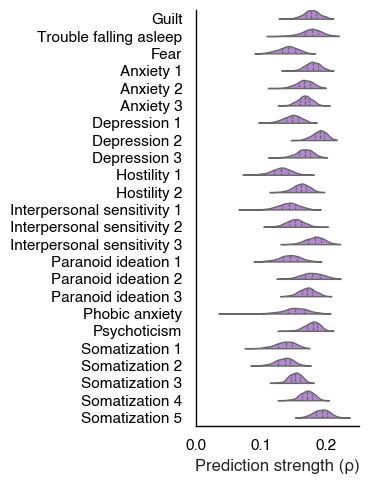

In [9]:
################### Plot significant symptom predictions for Figure 1a

plot_df = pd.DataFrame(
    BSI_preds_sorted_sig,
    columns=BSI_labels_plot
)

plot_df_long = plot_df.melt(
    var_name='Symptom',
    value_name='Prediction'
)

plot_df_long['Symptom'] = pd.Categorical(
    plot_df_long['Symptom'],
    categories=BSI_labels_plot,
    ordered=True
)

plt.figure(figsize=(4, 5), facecolor='white')

ax = plt.gca()
ax.set_facecolor('white')

sns.violinplot(
    data=plot_df_long,
    y='Symptom',
    x='Prediction',
    orient='h',
    inner='quartile',
    cut=0,
    color='#B57EDC',   # lighter purple
    linewidth=1,
    width=1.2          # wider violins
)


for violin in ax.collections:

    path = violin.get_paths()[0]
    verts = path.vertices

    center = np.mean(verts[:, 1])

    # squash upper half onto center line
    verts[verts[:, 1] > center, 1] = center
    

for line in ax.lines:

    xdata = line.get_xdata()
    ydata = line.get_ydata()

    center = np.mean(ydata)

    # squash upper half onto center
    ydata[ydata > center] = center

    line.set_ydata(ydata)


ax.set_xlim(0, 0.25)

ax.set_ylabel('')
ax.set_xlabel('Prediction strength (ρ)')

# Draw axes
for spine in ['left', 'bottom']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_color('black')
    ax.spines[spine].set_linewidth(1)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis='both', colors='black')

plt.tight_layout()

plt.savefig(
    "Figures/Figure1a.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

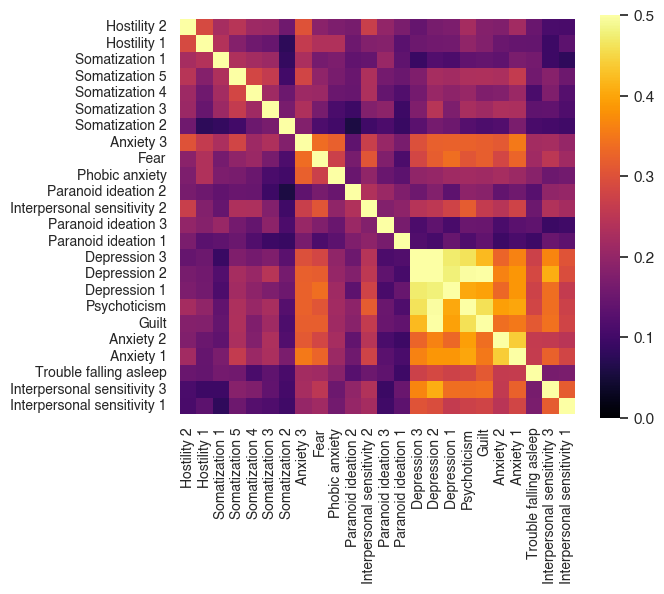

In [10]:
# Examine symptom network similarities reported in figure 1b

# Filter by significance
BSI_raw_sig = BSI_raw_sorted[:,issig]
BSI_networks_sig_pos = BSI_networks_pos_sorted[:,issig]
BSI_networks_sig_neg = BSI_networks_neg_sorted[:,issig]
BSI_networks_sig = BSI_networks_sorted[:,issig]

# Compute Dice similarity of each symptom network
def dice_coefficient(column1, column2):
    intersection = np.sum(column1 & column2)
    size1 = np.sum(column1)
    size2 = np.sum(column2)
    return (2 * intersection) / (size1 + size2) if (size1 + size2) > 0 else 0

BSI_dice = np.zeros((BSI_networks_sig.shape[1],BSI_networks_sig.shape[1]))

for n in range(BSI_networks_sig.shape[1]):
    for nn in range(BSI_networks_sig.shape[1]):
        
        netA = BSI_networks_sig[:,n]
        netB = BSI_networks_sig[:,nn]
        
        BSI_dice[n,nn] = dice_coefficient(netA, netB)
        
BSI_dice_df = pd.DataFrame(
    BSI_dice,
    index=BSI_labels_plot,
    columns=BSI_labels_plot
)

# Sort using hierarchical clustering

dice_matrix = BSI_dice_df.values

distance_matrix = 1 - dice_matrix

condensed_distance = sch.distance.squareform(
    distance_matrix,
    checks=False
)

linkage_matrix = sch.linkage(
    condensed_distance,
    method='ward'
)

dendro = sch.dendrogram(
    linkage_matrix,
    no_plot=True
)

sorted_ixs = dendro['leaves'][::-1]

# Convert labels to numpy array
BSI_labels_plot_arr = np.array(BSI_labels_plot)

sorted_BSI_lbls = BSI_labels_plot_arr[sorted_ixs]

# Reorder dataframe
sorted_BSI_dice_df = BSI_dice_df.loc[
    sorted_BSI_lbls,
    sorted_BSI_lbls
]

# Plot heatmap of network similarity
fig = plt.figure(figsize=(7, 6), facecolor='white')

ax = sns.heatmap(
    sorted_BSI_dice_df,
    vmin=0,
    vmax=0.5,
    cmap='inferno',
    square=True,
    cbar=True,
    linecolor='gray'
)

plt.xticks(
    rotation=90,
    fontsize=10
)

plt.yticks(
    rotation=0,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "Figures/Figure1b.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

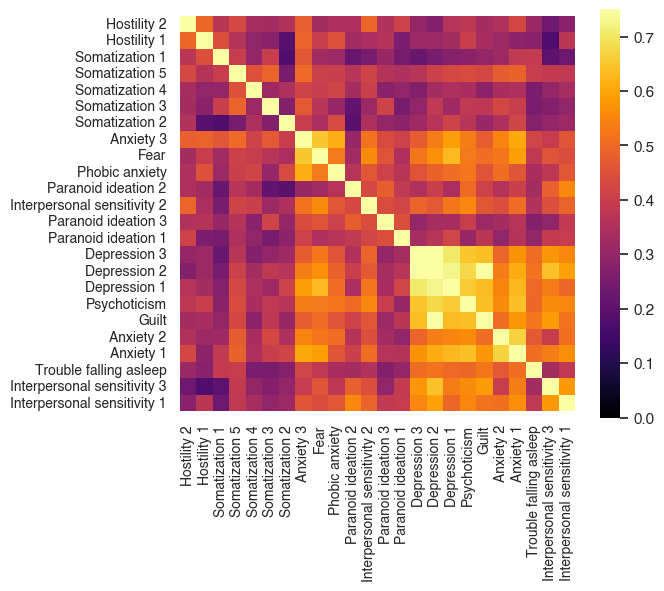

In [11]:
# Show correlations between symptom measures reported in Supplemental Fig 2
BSI_raw_sig_sorted = BSI_raw_sig[:,sorted_ixs]

BSI_raw_sig_sorted = np.asarray(BSI_raw_sig_sorted, dtype=float)

n_vars = BSI_raw_sig_sorted.shape[1]
BSI_raw_corrs = np.full((n_vars, n_vars), np.nan)

for i in range(n_vars):
    for j in range(i, n_vars):
        valid = ~np.isnan(BSI_raw_sig_sorted[:, i]) & ~np.isnan(BSI_raw_sig_sorted[:, j])
        if np.sum(valid) >= 2:
            r = np.corrcoef(BSI_raw_sig_sorted[valid, i], BSI_raw_sig_sorted[valid, j])[0, 1]
            BSI_raw_corrs[i, j] = r
            BSI_raw_corrs[j, i] = r
            

BSI_raw_corrs_df = pd.DataFrame(
    BSI_raw_corrs,
    index=sorted_BSI_lbls,
    columns=sorted_BSI_lbls
)

# Plot correlation matrix of measures
fig = plt.figure(figsize=(7, 6), facecolor='white')

ax = sns.heatmap(
    BSI_raw_corrs_df,
    vmin=0,
    vmax=0.75,
    cmap='inferno',
    square=True,
    cbar=True,
    linecolor='gray'
)

plt.xticks(
    rotation=90,
    fontsize=10
)

plt.yticks(
    rotation=0,
    fontsize=10
)

plt.tight_layout()

plt.savefig(
    "Figures/Supplemental_Figure2.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [12]:
BSI_raw_corrs_vec = BSI_raw_corrs_df.values[
    np.tril_indices_from(BSI_raw_corrs_df, k=-1)
]

sorted_BSI_dice_vec = sorted_BSI_dice_df.values[
    np.tril_indices_from(sorted_BSI_dice_df, k=-1)
]

r,p = pearsonr(BSI_raw_corrs_vec,sorted_BSI_dice_vec)
r

0.907290021769463

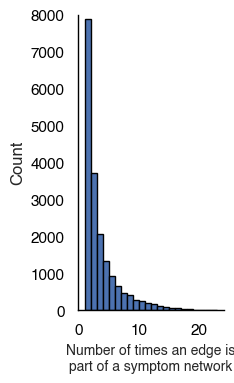

In [13]:
# Plot histogram showing how many times an edge appears in a symptom network (figure 1c)
BSI_networks_sums = np.sum(BSI_networks_sig, axis=1)

min_val = np.min(BSI_networks_sums)
max_val = np.max(BSI_networks_sums)

bins = np.arange(min_val+1, max_val + 1, 1)

plt.figure(figsize=(2.5, 4), facecolor='white')

ax = plt.gca()
ax.set_facecolor('white')

plt.hist(
    BSI_networks_sums,
    bins=bins,
    # color='gray',
    edgecolor='black'
)

plt.xlabel('Number of times an edge is\npart of a symptom network',fontsize=10)
plt.ylabel('Count')

plt.ylim([0, 8000])

# Draw axes
for spine in ['left', 'bottom']:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_color('black')
    ax.spines[spine].set_linewidth(1)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

ax.tick_params(axis='both', colors='black')

plt.tight_layout()

plt.savefig(
    "Figures/Figure1c.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [14]:
# Show where in the brain the edges of the symptom networks tend to localize to (figure 1d)

# Convert each symptom network to a matrix. 
BSI_networks_mats = np.zeros((268,268,BSI_networks_sig.shape[1]))

for n in range(BSI_networks_sig.shape[1]):
    
    tempmat = np.zeros((268,268))
    ix = -1

    for r in range(268):
        for c in range(268):
            if r < c:
                ix=ix+1
                tempmat[r,c] = BSI_networks_sig[ix,n]

            elif r == c:
                tempmat[r,c] = 0
                
    tempmat = tempmat + tempmat.T
    
    BSI_networks_mats[:,:,n] = tempmat
    
#Sum matrices.
BSI_networks_mats_sum = np.nansum(BSI_networks_mats, axis=2)

#Sort based on yeo networks
labels_df = pd.read_csv("/Users/ajsimon/Dropbox/Manuscripts/Disordered circuits/code/Input_data/Parc268toYeo17netlabel_CBL_SUB_BS.txt", header=None, sep="\t")

# Define network names
network_names = ['Vis A', 'Vis B', 'SM A', 'SM B', 'DAN A', 'DAN B', 'VAN A', 'VAN B', 'Lim A', 'Lim B', 'FPCN A', 'FPCN B', 'FPCN C', 'DMN A', 'DMN B', 'DMN C', 'Temp par', 'Cer', 'Sub', 'BS']

# Assign each node to a network
network_assignments = labels_df.values.argmax(axis=1)

# sort indices based on network assignments
sorted_net_ixs = np.argsort(network_assignments)
sorted_network_assignments = network_assignments[sorted_net_ixs]

BSI_networks_mats_sum_sorted = BSI_networks_mats_sum[np.ix_(sorted_net_ixs, sorted_net_ixs)]

# Find where each network block ends
boundaries = []
current_net = sorted_network_assignments[0]
for i in range(1, len(sorted_network_assignments)):
    if sorted_network_assignments[i] != current_net:
        boundaries.append(i)
        current_net = sorted_network_assignments[i]
        
# Compute tick positions for network labels
tick_positions = []
last_ix = 0
for net in range(len(network_names)):
    count = np.sum(sorted_network_assignments == net)
    tick_positions.append(last_ix + count // 2)
    last_ix += count
        
# Compute tick positions for network labels
tick_positions = []
last_ix = 0
for net in range(len(network_names)):
    count = np.sum(sorted_network_assignments == net)
    tick_positions.append(last_ix + count // 2)
    last_ix += count

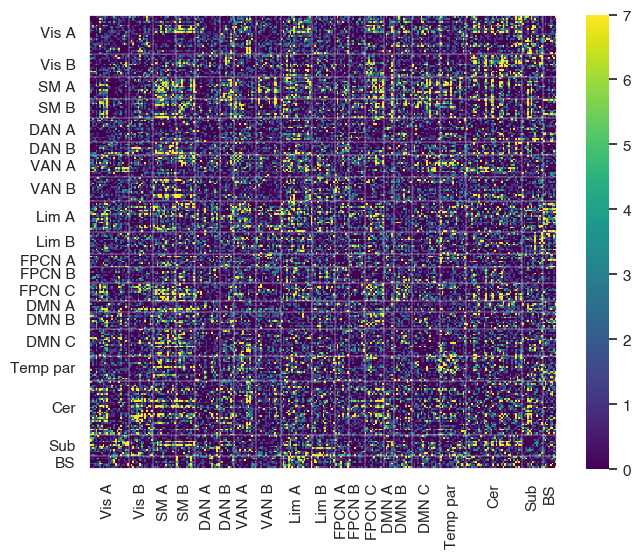

In [15]:
plt.figure(figsize=(7, 5.75))
plt.gca().set_facecolor('black')

ax = sns.heatmap(BSI_networks_mats_sum_sorted, annot=False, cmap='viridis', cbar=True, vmin = 0, vmax = 7)

ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

# Add white lines to separate networks
for boundary in boundaries:
    ax.axhline(boundary, color='white', lw=0.3)
    ax.axvline(boundary, color='white', lw=0.3)

# Add custom tick labels
plt.yticks(tick_positions, network_names, rotation=0, fontsize=11)
plt.xticks(tick_positions, network_names, rotation=90, fontsize=11)


# Remove tick marks using tick_params
ax.tick_params(left=False, bottom=False) 
for _, spine in ax.spines.items():
    spine.set_visible(True)
    
plt.tight_layout()

# plt.savefig(
#     "Figures/Figure1d.svg",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white"
# )

plt.show()

# Examine network heterogeneity

In [16]:
# Scale raw scores from 1-10
BSI_raw_z = zscore(BSI_raw_sig,axis=0, nan_policy='omit')

n_rows, n_cols = BSI_raw_z.shape

normData = np.zeros_like(BSI_raw_z, dtype=float)

epsilon = 0.01

for c in range(n_cols):
    col = BSI_raw_z[:, c].astype(float)

    colMin = np.nanmin(col)
    colMax = np.nanmax(col)

    # Min-max normalize to [0, 1]
    colNorm = (col - colMin) / (colMax - colMin)

    # Shrink slightly so it's strictly inside (0,1)
    colNorm = colNorm * (1 - 2*epsilon) + epsilon

    # Scale to [1, 10]
    colScaled = 1 + colNorm * 9   # (10 − 1)

    normData[:, c] = colScaled

In [17]:
def edgewise_residuals_from_y(E, y):
    """
    For each edge, fit:
        edge = b0 + b1*y
    across subjects, then return residuals:
        observed_edge - predicted_edge

    Parameters
    ----------
    E : ndarray, shape (n_edges, n_subjects)
        Edge values for a symptom network mask.
    y : ndarray, shape (n_subjects,)
        Symptom scores.

    Returns
    -------
    E_res : ndarray, shape (n_edges, n_valid_subjects)
        Residuals for each edge x subject.
    valid : ndarray, shape (n_subjects,)
        Boolean mask of subjects retained after removing NaNs in y.
    """
    E = np.asarray(E, dtype=float)
    y = np.asarray(y, dtype=float).ravel()

    # Keep only subjects with valid y
    valid = ~np.isnan(y)
    E = E[:, valid]
    y = y[valid]

    # Design matrix: intercept + y
    X = np.column_stack((np.ones_like(y), y))   # subjects x 2

    # Solve all edgewise regressions at once
    # beta has shape (2, n_edges)
    beta, _, _, _ = np.linalg.lstsq(X, E.T, rcond=None)

    # Predicted edge values for each subject
    # shape: subjects x edges -> transpose to edges x subjects
    E_hat = (X @ beta).T

    # Residual distance from each observed edge value to the fitted line
    E_res = E - E_hat

    return E_res, valid

In [18]:
circ_disorder = np.zeros((BSI_networks_sig.shape[1], BSI_networks_sig.shape[0], normData.shape[0]))   # 24 x 35778 x 317

E_Zres_pos_list = []
E_Zres_neg_list = []
E_Zres_both_list = []

n_subj_total = vectors.shape[1]


for m in range(BSI_networks_sig.shape[1]):  # 24
    
    y = BSI_raw_sig[:, m]
        
    ################## calculate residuals from fit line in the pos network 
    mask_pos = BSI_networks_sig_pos[:, m] != 0
    E_pos = vectors[mask_pos, :]

    E_res_pos, valid_pos = edgewise_residuals_from_y(E_pos, y)
    
    resid_sd_pos = np.nanstd(
        E_res_pos,
        axis=1,
        ddof=1,
        keepdims=True
    )

    resid_sd_pos[resid_sd_pos == 0] = np.nan

    E_Zres_pos = E_res_pos / resid_sd_pos

    E_Zres_pos_full = np.full(
        (E_Zres_pos.shape[0], n_subj_total),
        np.nan,
        dtype=np.float32
    )

    E_Zres_pos_full[:, valid_pos] = E_Zres_pos
    
    # Normalize -- scale from 1-10
    E_res_pos_z = zscore(E_res_pos,axis=1, nan_policy='omit')

    n_rows, n_cols = E_res_pos_z.shape

    normEdges_pos = np.zeros_like(E_res_pos_z, dtype=float)

    epsilon = 0.01

    for r in range(n_rows):
        row = E_res_pos_z[r, :].astype(float)

        rowMin = np.nanmin(row)
        rowMax = np.nanmax(row)

        # Min-max normalize to [0, 1]
        rowNorm = (row - rowMin) / (rowMax - rowMin)

        # Shrink slightly so it's strictly inside (0,1)
        rowNorm = rowNorm * (1 - 2*epsilon) + epsilon

        # Scale to [1, 10]
        rowScaled = 1 + rowNorm * 9   # (10 − 1)

        normEdges_pos[r, :] = rowScaled
    
    # Incorporate into circ_disorder -- skip over subjects with nans for y data
    circ_disorder[m, :, :][np.ix_(mask_pos, valid_pos)] = normEdges_pos
    

    #################### calculate residuals from fit line in the neg network 
    mask_neg = BSI_networks_sig_neg[:, m] != 0
    E_neg = vectors[mask_neg, :]

    E_res_neg, valid_neg = edgewise_residuals_from_y(E_neg, y)
    
    resid_sd_neg = np.nanstd(
        E_res_neg,
        axis=1,
        ddof=1,
        keepdims=True
    )

    resid_sd_neg[resid_sd_neg == 0] = np.nan

    E_Zres_neg = E_res_neg / resid_sd_neg

    E_Zres_neg_full = np.full(
        (E_Zres_neg.shape[0], n_subj_total),
        np.nan,
        dtype=np.float32
    )

    E_Zres_neg_full[:, valid_neg] = E_Zres_neg

    ###### Combine pos and neg networks

    E_Zres_both_full = np.concatenate(
        (
            E_Zres_pos_full,
            -E_Zres_neg_full
        ),
        axis=0
    )

    E_Zres_pos_list.append(E_Zres_pos_full)
    E_Zres_neg_list.append(E_Zres_neg_full)
    E_Zres_both_list.append(E_Zres_both_full)
    
    # Normalize -- scale from 1-10
    E_res_neg = E_res_neg*-1
    E_res_neg_z = zscore(E_res_neg,axis=1, nan_policy='omit')

    n_rows, n_cols = E_res_neg_z.shape

    normEdges_neg = np.zeros_like(E_res_neg_z, dtype=float)

    epsilon = 0.01

    for r in range(n_rows):
        row = E_res_neg_z[r, :].astype(float)

        rowMin = np.nanmin(row)
        rowMax = np.nanmax(row)

        # Min-max normalize to [0, 1]
        rowNorm = (row - rowMin) / (rowMax - rowMin)

        # Shrink slightly so it's strictly inside (0,1)
        rowNorm = rowNorm * (1 - 2*epsilon) + epsilon

        # Scale to [1, 10]
        rowScaled = 1 + rowNorm * 9   # (10 − 1)

        normEdges_neg[r, :] = rowScaled
    
    # Incorporate into circ_disorder -- skip over subjects with nans for y data
    circ_disorder[m, :, :][np.ix_(mask_neg, valid_neg)] = normEdges_neg
    

In [22]:
BSI_networks_sig.shape

fear_network_mask_pos = BSI_networks_sig_pos[:,2]
fear_network_mask_neg = BSI_networks_sig_neg[:,2]

scaled_fear_edges_pos = E_Zres_pos_list[2]
scaled_fear_edges_neg = E_Zres_neg_list[2]

# BSI_labels_plot[2]

fear_edges_pos_full = np.zeros((35778, 317))
fear_edges_neg_full = np.zeros((35778, 317))

# Fill network edges with scaled values
fear_edges_pos_full[fear_network_mask_pos.astype(bool), :] = scaled_fear_edges_pos
fear_edges_neg_full[fear_network_mask_neg.astype(bool), :] = scaled_fear_edges_neg

fear_edges_combined = fear_edges_pos_full - fear_edges_neg_full

fear_symp = BSI_raw_z[:,2]

fear_net_sum = (
    np.sum(vectors_z[fear_network_mask_pos == 1, :], axis=0)
    - np.sum(vectors_z[fear_network_mask_neg == 1, :], axis=0)
)

In [26]:
# Find 2 subjects with identical fear symptoms who also have very similar fear network connectivity values

fear_symp = np.asarray(fear_symp).ravel()
fear_net_sum = np.asarray(fear_net_sum).ravel()

scaled_fear_edges_both = E_Zres_both_list[2]

tolerance = 0.1  # Fear symptom values between 2.1 and 2.3

for i in range(len(fear_symp)):
    for j in range(i + 1, len(fear_symp)):
        if (abs(fear_symp[i] - 2.2) <= tolerance and
            abs(fear_symp[j] - 2.2) <= tolerance and
            abs(fear_net_sum[i] - fear_net_sum[j]) <= 150):

            print(f"Subjects: {i}, {j}")
            print(f"Fear symptoms: {fear_symp[i]:.3f}, {fear_symp[j]:.3f}")
            print(f"Fear network sums: {fear_net_sum[i]:.2f}, {fear_net_sum[j]:.2f}")
            
            r = np.corrcoef(
                scaled_fear_edges_both[:, i],
                scaled_fear_edges_both[:, j]
            )[0, 1]
            
            fear_edges_subj_A_all = fear_edges_combined[:, i]
            fear_edges_subj_B_all = fear_edges_combined[:, j]
            
            fear_edges_subj_A = scaled_fear_edges_both[:, i]
            fear_edges_subj_B = scaled_fear_edges_both[:, j]

            print(f"Correlation between subjects {i} and {j}: r = {r:.4f}")
            break
    else:
        continue
    break

Subjects: 27, 115
Fear symptoms: 2.224, 2.224
Fear network sums: 1067.66, 969.37
Correlation between subjects 27 and 115: r = -0.0029


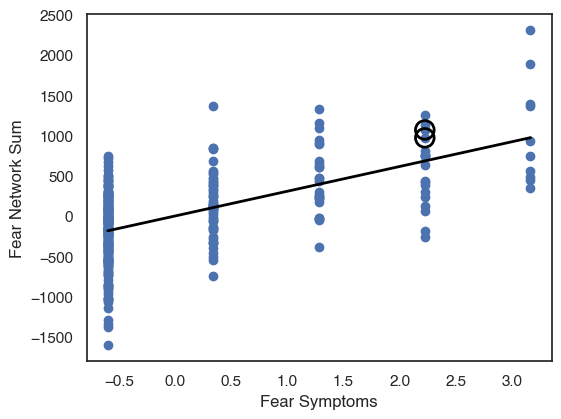

In [28]:
# Make plot for fig2a
valid = np.isfinite(fear_symp) & np.isfinite(fear_net_sum)

x = fear_symp[valid]
y = fear_net_sum[valid]

# Scatterplot
plt.figure(figsize=(6, 4.5))
plt.scatter(x, y)

# Fit regression line
slope, intercept = np.polyfit(x, y, 1)
x_fit = np.linspace(x.min(), x.max(), 100)
y_fit = slope * x_fit + intercept

plt.plot(x_fit, y_fit, color='black', linewidth=2)

# Highlight selected subjects with black circles
plt.scatter(
    fear_symp[[i, j]],
    fear_net_sum[[i, j]],
    s=180,
    facecolors='none',
    edgecolors='black',
    linewidths=2,
    zorder=10
)

plt.xlabel('Fear Symptoms')
plt.ylabel('Fear Network Sum')
plt.show()

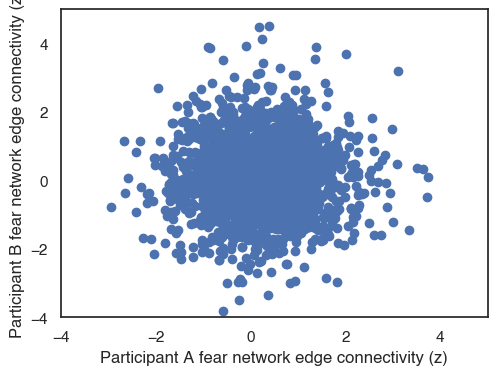

In [29]:
x = fear_edges_subj_A
y = fear_edges_subj_B

# Scatterplot
plt.figure(figsize=(5.5, 4))
plt.scatter(x, y)

plt.xlim(-4, 5)
plt.ylim(-4, 5)

plt.xticks(np.arange(-4, 6, 2))
plt.yticks(np.arange(-4, 6, 2))

plt.xlabel('Participant A fear network edge connectivity (z)')
plt.ylabel('Participant B fear network edge connectivity (z)')
plt.show()

In [30]:
# Compute subject-subject edge residual correlations for each symptom network
# Test whether the observed kurtosis was greater than chance via permutation testing

n_subj_total = vectors.shape[1]
n_symp = BSI_raw_sig.shape[1]

n_null = 10
rng = np.random.default_rng(0)

corr_mats_both = []

null_corr_vecs_both = []

kurtosis_obs = np.full(n_symp, np.nan)
kurt_p_vals = np.full(n_symp, np.nan)

for s in range(n_symp):

    y = BSI_raw_sig[:, s]

    E_Zres_both_full = E_Zres_both_list[s]

    valid_subjects = ~np.all(
        np.isnan(E_Zres_both_full),
        axis=0
    )

    X = E_Zres_both_full[:, valid_subjects].T

    n_valid_subj = X.shape[0]

    if n_valid_subj < 3 or X.shape[1] < 2:
        corr_mats_both.append(
            np.full(
                (n_valid_subj, n_valid_subj),
                np.nan,
                dtype=np.float32
            )
        )

        null_corr_vecs_both.append(
            np.empty((n_null, 0), dtype=np.float32)
        )

        continue

    ##### Compute all pairwise subject correlations

    # Rows are subjects, so rowvar=True is correct
    C_both = np.corrcoef(X)

    corr_mats_both.append(C_both)

    lower_tri_idx = np.tril_indices(
        n_valid_subj,
        k=-1
    )

    n_pairs = len(lower_tri_idx[0])

    C_both_vec = C_both[lower_tri_idx]

    kurtosis_obs[s] = kurtosis(
        C_both_vec,
        fisher=True,
        bias=False,
        nan_policy="omit"
    )

    ##### compute null correlations

    null_corr_vectors = np.full(
        (n_null, n_pairs),
        np.nan,
        dtype=np.float32
    )

    kurtosis_null = np.full(
        n_null,
        np.nan
    )

    for perm in range(n_null):

        # X is subjects × edges.
        # Independently permute edge values within each subject.
        X_shuffled = rng.permuted(
            X,
            axis=1
        )

        # Rows remain subjects
        C_null = np.corrcoef(X_shuffled)

        C_null_vec = C_null[lower_tri_idx]

        null_corr_vectors[perm, :] = C_null_vec

        kurtosis_null[perm] = kurtosis(
            C_null_vec,
            fisher=True,
            bias=False,
            nan_policy="omit"
        )

    null_corr_vecs_both.append(
        null_corr_vectors
    )

    # One-sided permutation p-value:
    # observed kurtosis greater than expected under the null
    valid_null_kurt = np.isfinite(kurtosis_null)

    if np.any(valid_null_kurt):
        kurt_p_vals[s] = (
            np.sum(
                kurtosis_null[valid_null_kurt]
                >= kurtosis_obs[s]
            )
        ) / (
            np.sum(valid_null_kurt)
        )

    print(
        f"Symptom {s + 1}/{n_symp}: "
        f"n={n_valid_subj}, "
        f"kurtosis={kurtosis_obs[s]:.4f}, "
        f"p={kurt_p_vals[s]:.4f}"
    )

Symptom 1/24: n=315, kurtosis=0.3948, p=0.0000
Symptom 2/24: n=316, kurtosis=0.4042, p=0.0000
Symptom 3/24: n=316, kurtosis=0.4914, p=0.0000
Symptom 4/24: n=316, kurtosis=0.3808, p=0.0000
Symptom 5/24: n=315, kurtosis=0.3848, p=0.0000
Symptom 6/24: n=316, kurtosis=0.5723, p=0.0000
Symptom 7/24: n=316, kurtosis=0.4551, p=0.0000
Symptom 8/24: n=315, kurtosis=0.4768, p=0.0000
Symptom 9/24: n=316, kurtosis=0.4775, p=0.0000
Symptom 10/24: n=316, kurtosis=0.3655, p=0.0000
Symptom 11/24: n=315, kurtosis=0.4101, p=0.0000
Symptom 12/24: n=316, kurtosis=0.3388, p=0.0000
Symptom 13/24: n=316, kurtosis=0.4659, p=0.0000
Symptom 14/24: n=316, kurtosis=0.3562, p=0.0000
Symptom 15/24: n=316, kurtosis=0.3342, p=0.0000
Symptom 16/24: n=316, kurtosis=0.3441, p=0.0000
Symptom 17/24: n=316, kurtosis=0.2865, p=0.0000
Symptom 18/24: n=316, kurtosis=0.2887, p=0.0000
Symptom 19/24: n=316, kurtosis=0.4360, p=0.0000
Symptom 20/24: n=316, kurtosis=0.3782, p=0.0000
Symptom 21/24: n=316, kurtosis=0.4232, p=0.0000
S

<Axes: >

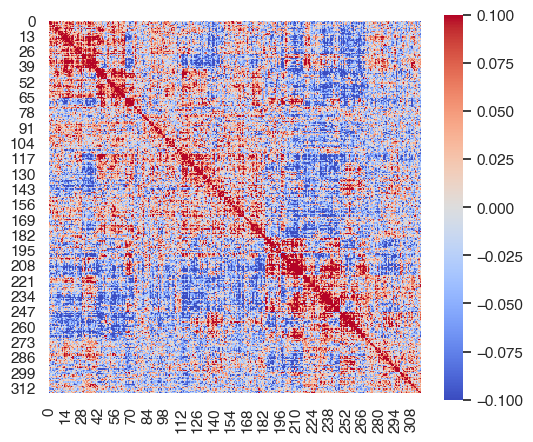

In [32]:
# Show intersubject similarity in how edge residuals are distributed in an example symptom network (fear) (Fig 2b)
edge_resid_corrmat = corr_mats_both[2]

# Convert correlation to distance
D = 1 - edge_resid_corrmat

# Ensure diagonal is exactly zero
np.fill_diagonal(D, 0)

# Convert to condensed distance vector
D_condensed = squareform(D, checks=False)

# Agglomerative hierarchical clustering
Z = linkage(D_condensed, method="ward")

# Order of subjects
order = leaves_list(Z)

# Sort the correlation matrix
edge_resid_corrmat_sorted = edge_resid_corrmat[np.ix_(order, order)]

plt.figure(figsize=(6, 5), facecolor="white")

sns.heatmap(edge_resid_corrmat_sorted,
    vmin=-.1, 
    vmax=0.1,
    cmap='coolwarm',
    square=True)

# plt.savefig(
#     "Figures/Figure2e.svg",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white"
# )

In [33]:
medians = []
stdevs = []

for mat in corr_mats_both:
    vals = mat[np.triu_indices_from(mat, k=1)]  # Upper triangle, excluding diagonal
    medians.append(np.nanmedian(vals))
    stdevs.append(np.nanstd(vals))

medians = np.array(medians)
stdevs = np.array(stdevs)

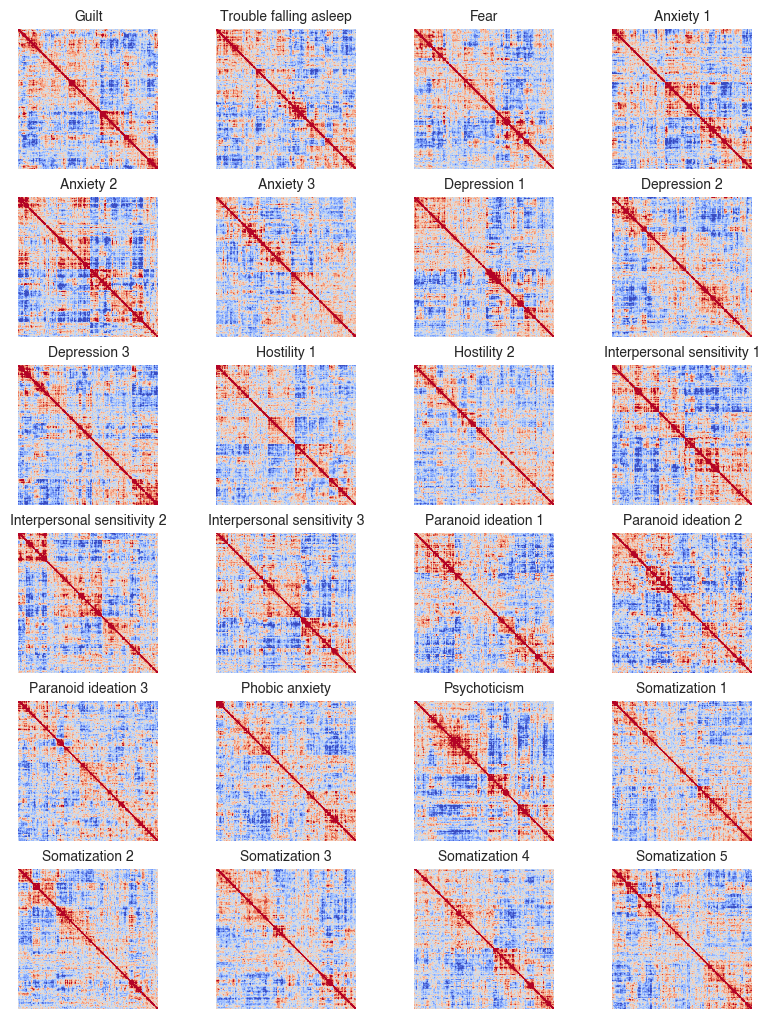

In [35]:
corrlabels_plot = ['Guilt', 'Trouble falling asleep', 'Fear',
       'Anxiety 1', 'Anxiety 2', 'Anxiety 3', 'Depression 1',
       'Depression 2', 'Depression 3',
       'Hostility 1','Hostility 2',
       'Interpersonal sensitivity 1',
       'Interpersonal sensitivity 2', 'Interpersonal sensitivity 3',
       'Paranoid ideation 1', 'Paranoid ideation 2', 'Paranoid ideation 3',
       'Phobic anxiety',
       'Psychoticism',
       'Somatization 1', 'Somatization 2',
       'Somatization 3', 'Somatization 4',
       'Somatization 5']


fig, axes = plt.subplots(
    6, 4,
    figsize=(8, 10),
    facecolor='white'
)

axes = axes.ravel()

for ii in range(24):

    ax = axes[ii]
    ax.set_facecolor('white')

    edge_resid_corrmat = corr_mats_both[ii]

    # Convert correlation to distance
    D = 1 - edge_resid_corrmat

    # Ensure diagonal is exactly zero
    np.fill_diagonal(D, 0)

    # Convert to condensed distance vector
    D_condensed = squareform(D, checks=False)

    # Agglomerative hierarchical clustering
    Z = linkage(D_condensed, method="ward")

    # Order of subjects
    order = leaves_list(Z)

    # Sort the correlation matrix
    edge_resid_corrmat_sorted = edge_resid_corrmat[np.ix_(order, order)]

    # Plot
    im = ax.imshow(
        edge_resid_corrmat_sorted,
        aspect='equal',
        origin='upper',
        vmin=-.1,
        vmax=0.1,
        cmap='coolwarm'
    )

    ax.set_title(corrlabels_plot[ii], fontsize=10)

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)


plt.tight_layout()

plt.subplots_adjust(
    left=0.0,
    right=0.99,
    bottom=0.0,
    top=0.98,
    wspace=0.00,
    hspace=0.2
)

# plt.savefig(
#     "Figures/Supplemental_Figure3.svg",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white"
# )

plt.show()

In [36]:
nsymp = len(null_corr_vecs_both)
null_corr_vecs_median = []
corr_vecs = []

# loop through number of symptoms
for s in range(nsymp):

    # find perm with median kurtosis in null_corr_vecs_both[s]
    nperm = null_corr_vecs_both[s].shape[0]
    kurts = np.zeros((nperm))
    
    for it in range(nperm):
        
        thisrandomdist = null_corr_vecs_both[s][it,:]
        
        kurts[it] = kurtosis(
            thisrandomdist,
            fisher=True,
            bias=False,
            nan_policy="omit"
        )

    median_idx = np.argmin(np.abs(kurts - np.median(kurts)))
    median_null = null_corr_vecs_both[s][median_idx,:]
    
    null_corr_vecs_median.append(median_null)
    
    del kurts, median_idx, median_null


    thiscorrmat = corr_mats_both[s]
    
    n_valid_subj = thiscorrmat.shape[0]

    lower_tri_idx = np.tril_indices(
        n_valid_subj,
        k=-1
    )

    thiscorrvec = thiscorrmat[lower_tri_idx]
    corr_vecs.append(thiscorrvec)

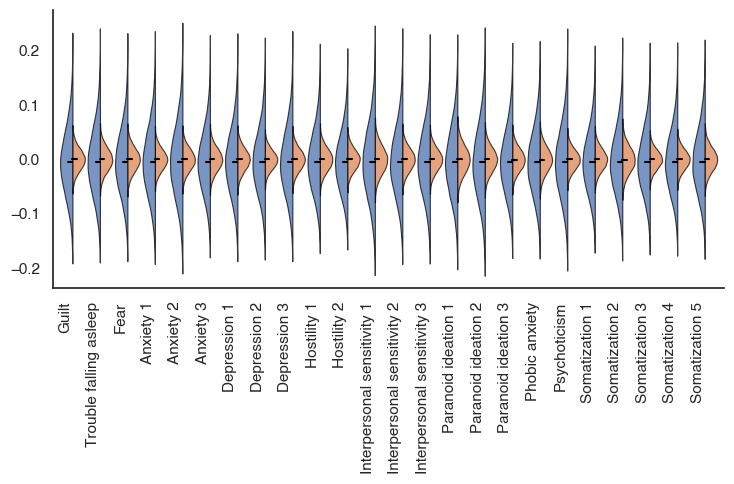

In [38]:
def clip_for_violin(x, lower_pct=1, upper_pct=99):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    lower = np.percentile(x, lower_pct)
    upper = np.percentile(x, upper_pct)

    return np.clip(x, lower, upper)


n_symp = len(corrlabels_plot)
positions = np.arange(n_symp)

# Remove NaNs and convert each item to a 1D array
corr_data = [
    np.asarray(corr_vecs[i], dtype=float).ravel()
    for i in range(n_symp)
]

null_data = [
    np.asarray(null_corr_vecs_median[i], dtype=float).ravel()
    for i in range(n_symp)
]

corr_data = [
    clip_for_violin(x, lower_pct=.1, upper_pct=99.9)
    for x in corr_data
]

null_data = [
    clip_for_violin(x, lower_pct=.1, upper_pct=99.9)
    for x in null_data
]

fig, ax = plt.subplots(
    figsize=(7.5, 5),
    facecolor="white"
)

ax.set_facecolor("white")


vp_obs = ax.violinplot(
    corr_data,
    positions=positions,
    widths=0.9,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for i, body in enumerate(vp_obs["bodies"]):

    # Keep only the left side of the violin
    vertices = body.get_paths()[0].vertices
    vertices[:, 0] = np.minimum(
        vertices[:, 0],
        positions[i]
    )

    body.set_facecolor("C0")
    body.set_edgecolor("black")
    body.set_alpha(0.75)
    body.set_linewidth(0.8)



vp_null = ax.violinplot(
    null_data,
    positions=positions,
    widths=0.9,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for i, body in enumerate(vp_null["bodies"]):

    # Keep only the right side of the violin
    vertices = body.get_paths()[0].vertices
    vertices[:, 0] = np.maximum(
        vertices[:, 0],
        positions[i]
    )

    body.set_facecolor("C1")
    body.set_edgecolor("black")
    body.set_alpha(0.75)
    body.set_linewidth(0.8)


obs_medians = np.array([
    np.median(x) if len(x) > 0 else np.nan
    for x in corr_data
])

null_medians = np.array([
    np.median(x) if len(x) > 0 else np.nan
    for x in null_data
])

# Small horizontal lines extending into each half
median_width = 0.16

for i in range(n_symp):

    if np.isfinite(obs_medians[i]):
        ax.plot(
            [positions[i] - median_width, positions[i]],
            [obs_medians[i], obs_medians[i]],
            color="black",
            linewidth=1.5,
            zorder=3
        )

    if np.isfinite(null_medians[i]):
        ax.plot(
            [positions[i], positions[i] + median_width],
            [null_medians[i], null_medians[i]],
            color="black",
            linewidth=1.5,
            zorder=3
        )


ax.set_xticks(positions)
ax.set_xticklabels(
    corrlabels_plot,
    rotation=90,
    ha="right"
)



ax.set_xlim(
    -0.7,
    n_symp - 0.3
)



legend_handles = [
    Patch(
        facecolor="C0",
        edgecolor="black",
        alpha=0.75,
        label="Observed"
    ),
    Patch(
        facecolor="C1",
        edgecolor="black",
        alpha=0.75,
        label="Null"
    )
]

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "Figures/Figure2c.svg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Build disordered circuit models

In [39]:
Weighted_CPMnets_vecs = np.empty((BSI_networks_sig.shape[0], normData.shape[0]))
Weighted_CPMnets_vecs_control = np.empty((BSI_networks_sig.shape[0], normData.shape[0]))  # this one is not weighted by residuals

Sum_BSI_nets = np.nansum(BSI_networks_sig[:,:],axis=1)

for n in range(normData.shape[0]):  # 317
    
    Weighted_vecs_temp = np.empty((BSI_networks_sig.shape[0], BSI_networks_sig.shape[1]))
    Weighted_vecs_temp_control = np.empty((BSI_networks_sig.shape[0], BSI_networks_sig.shape[1]))

    for m in range(BSI_networks_sig.shape[1]):  # 24
        
        w1 = circ_disorder[m,:,n]   
        w2 = normData[n, m]

        Weighted_vecs_temp[:, m] = BSI_networks_sig[:, m] * (w1 + w2)
        Weighted_vecs_temp_control[:, m] = BSI_networks_sig[:, m] * (w2)
        
        
    Weighted_CPMnets_vecs[:,n] = (np.nansum(Weighted_vecs_temp, axis=1))
    Weighted_CPMnets_vecs_control[:,n] = (np.nansum(Weighted_vecs_temp_control, axis=1))

In [40]:
# Mask out edges that are never predictive for BSI items
mask = Sum_BSI_nets != 0
Sum_BSI_nets_nozeros = Sum_BSI_nets[mask]
Weighted_CPMnets_reduced = Weighted_CPMnets_vecs[mask,:]
Weighted_CPMnets_control_reduced = Weighted_CPMnets_vecs_control[mask,:]

In [41]:
# Normalize disordered circuit vectors by z-scoring
Weighted_CPMnets_z = zscore(
    Weighted_CPMnets_vecs,
    axis=1,
    nan_policy='omit'
)

Weighted_CPMnets_z_noZeros = Weighted_CPMnets_z[mask,:]

# Shift z-scored disordered circuit vectors so they're all positive
circuit_min = Weighted_CPMnets_z_noZeros.min()

Weighted_CPMnets_noZeros_norm = Weighted_CPMnets_z_noZeros + (-circuit_min)
Weighted_CPMnets_norm = Weighted_CPMnets_z + circuit_min

### Normalize the control vector
Weighted_CPMnets_z_control = zscore(
    Weighted_CPMnets_vecs_control,
    axis=1,
    nan_policy='omit'
)

Weighted_CPMnets_z_noZeros_control = Weighted_CPMnets_z_control[mask,:]

# Shift z-scored disordered circuit vectors so they're all positive
circuit_min_control = Weighted_CPMnets_z_noZeros_control.min()

Weighted_CPMnets_noZeros_norm_control = Weighted_CPMnets_z_noZeros_control + (-circuit_min_control)
Weighted_CPMnets_norm_control = Weighted_CPMnets_z + circuit_min_control

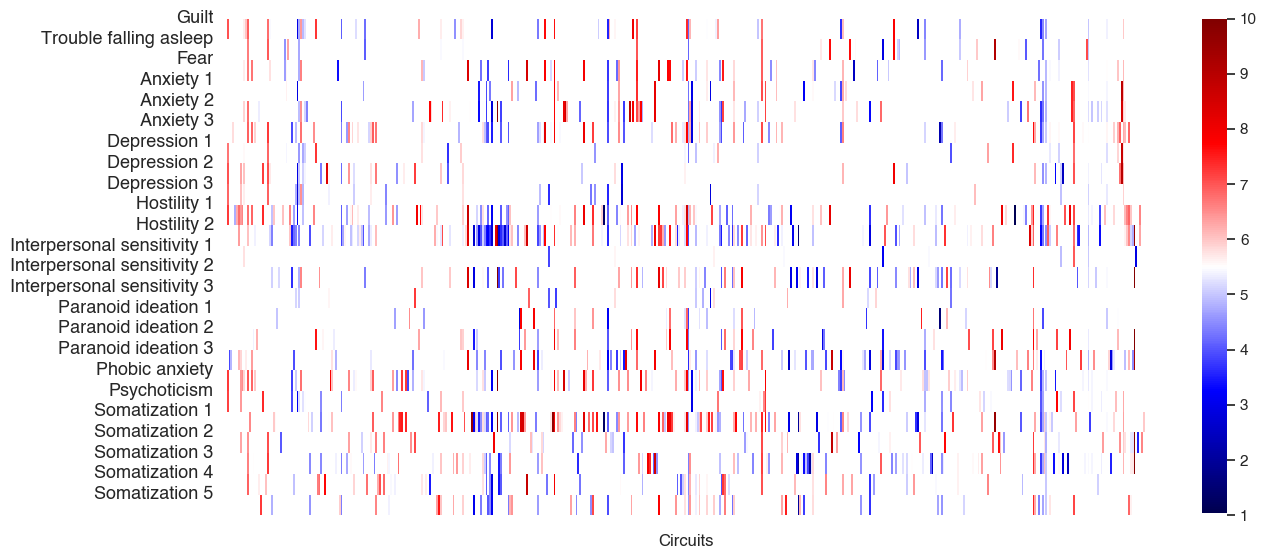

In [43]:
# Plot the edge masks for each symptom network color coded by that edges residual value for a single example subject (Fig 3a)

plot_data = circ_disorder[:, :, 123]   # 3rd dimension is subjects. Pick a random subject to display as an example

# Keep only columns that are not all zeros
nonzero_cols = ~(np.all(plot_data == 0, axis=0))
plot_data = plot_data[:, nonzero_cols]


sns.set(style='white', font='Helvetica')

# Create modified colormap: force 0 to be white
base_cmap = plt.cm.seismic
colors = base_cmap(np.linspace(0, 1, 256))
colors[0] = [1, 1, 1, 1]  # pure white at the minimum
cmap_white0 = ListedColormap(colors)

plt.figure(figsize=(14, 5.75), facecolor='white')
ax = plt.gca()
ax.set_facecolor('white')

ax = sns.heatmap(
    plot_data[:,:500],  #show first 500 edges
    cmap=cmap_white0,
    # cmap='viridis_r',
    cbar=True,
    vmin=1,
    vmax=10
)

ax.set_yticks(np.arange(len(BSI_labels_plot)))
ax.set_yticklabels(BSI_labels_plot, fontsize=13, rotation=0, va='center')
ax.set_xticklabels([])
ax.set_xlabel('Circuits')

plt.grid(False)
plt.tight_layout()

# plt.savefig(
#     "Figures/Figure3a.svg",
#     dpi=400,
#     bbox_inches="tight",
#     facecolor="white"
# )

plt.show()

In [44]:
BSI_raw_sig_trans = BSI_raw_sig.T

valid_cols = ~np.isnan(BSI_raw_sig_trans).all(axis=0)
bad_cols = np.where(np.isnan(BSI_raw_sig_trans).all(axis=0))[0]
print(bad_cols)

# Keep only those columns
Weighted_CPMnets_noZeros_norm = \
    Weighted_CPMnets_noZeros_norm[:, valid_cols]

Weighted_CPMnets_norm = \
    Weighted_CPMnets_norm[:, valid_cols]

Weighted_CPMnets_noZeros_norm_control = \
    Weighted_CPMnets_noZeros_norm_control[:, valid_cols]

Weighted_CPMnets_norm_control = \
    Weighted_CPMnets_norm_control[:, valid_cols]

normData_transposed = normData.T

normData_transposed = \
    normData_transposed[:, valid_cols]

mini_data_transposed = mini_data.T

mini_data_transposed = \
    mini_data_transposed[:,valid_cols]

[105]


In [45]:
# Sort subjects based on disordered circuit similarity using hierarchical clustering

#### impute & cluster
imputer = SimpleImputer(strategy='mean')
features_imputed = imputer.fit_transform(Weighted_CPMnets_noZeros_norm.T)

Z = linkage(features_imputed, method='ward', metric='euclidean')

# burden score: total disordered circuit load per subject
subject_burden = np.nansum(Weighted_CPMnets_noZeros_norm, axis=0)

# recursively order leaves
root, nodes = to_tree(Z, rd=True)

def get_order_by_burden(node, burden):
    """
    Recursively order leaves so that the child subtree with larger
    mean burden goes to the left.
    """
    if node.is_leaf():
        return [node.id], burden[node.id]

    left_order, left_mean = get_order_by_burden(node.left, burden)
    right_order, right_mean = get_order_by_burden(node.right, burden)

    # Put higher-burden subtree first
    if left_mean >= right_mean:
        order = left_order + right_order
    else:
        order = right_order + left_order

    mean_burden = np.mean(burden[order])
    return order, mean_burden

order, _ = get_order_by_burden(root, subject_burden)
order = np.array(order)

# apply order
Weighted_CPMnets_noZeros_norm_sorted = Weighted_CPMnets_noZeros_norm[:, order]
Weighted_CPMnets_norm_sorted = Weighted_CPMnets_norm[:,order]

mini_data_sorted = mini_data_transposed[:, order]
normData_sorted = normData_transposed[:, order]

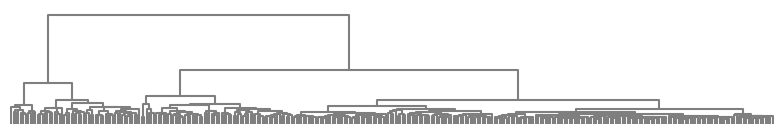

In [46]:
# Reorder linkage
def reorder_linkage_to_match_order(Z, order):
    Z_new = Z.copy()
    n = Z.shape[0] + 1

    target_pos = {leaf: i for i, leaf in enumerate(order)}

    # store leaves under each node
    leaves = {i: [i] for i in range(n)}

    for i in range(Z_new.shape[0]):
        node_id = n + i

        left = int(Z_new[i, 0])
        right = int(Z_new[i, 1])

        left_leaves = leaves[left]
        right_leaves = leaves[right]

        # If right subtree should come before left subtree, swap
        if min(target_pos[x] for x in right_leaves) < min(target_pos[x] for x in left_leaves):
            Z_new[i, 0], Z_new[i, 1] = Z_new[i, 1], Z_new[i, 0]
            left_leaves, right_leaves = right_leaves, left_leaves

        leaves[node_id] = left_leaves + right_leaves

    return Z_new

Z_ordered = reorder_linkage_to_match_order(Z, order)

plt.figure(figsize=(8, 1.5), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

dendrogram(
    Z_ordered,
    # labels=order,
    leaf_rotation=90,
    leaf_font_size=6,
    color_threshold=3000,
    link_color_func=lambda k: '#7f7f7f'   # gray
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [47]:
# sort the edges so we can see structure
imputer = SimpleImputer(strategy='mean')  # Impute nans with column mean
features_imputed_edges = imputer.fit_transform(Weighted_CPMnets_noZeros_norm_sorted)

# Perform hierarchical clustering
linkage_data_edges = linkage(features_imputed_edges, method='ward', metric='euclidean')

order_edges = leaves_list(linkage_data_edges)

Disordered_circuits = np.zeros((Weighted_CPMnets_noZeros_norm_sorted.shape[0],Weighted_CPMnets_noZeros_norm_sorted.shape[1]))

for o, feat in enumerate(order_edges):
    Disordered_circuits[o,:] = Weighted_CPMnets_noZeros_norm_sorted[order_edges[o],:]

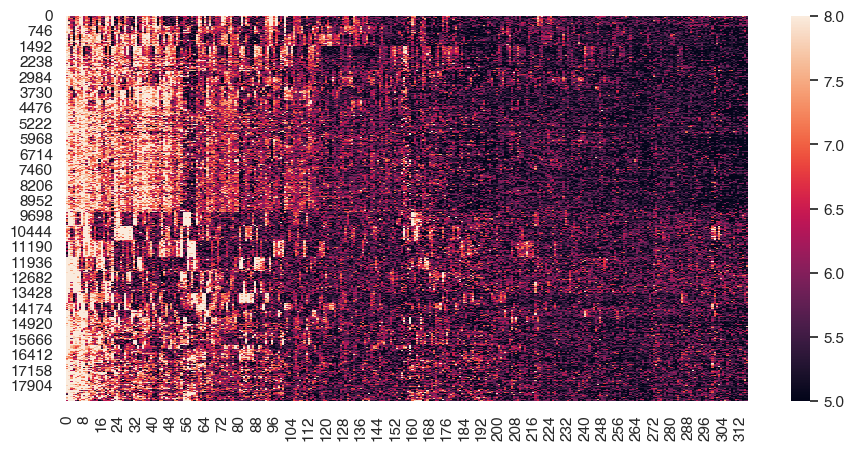

In [48]:
plt.figure(figsize=(11, 5))
plt.gca().set_facecolor('black')

ax = sns.heatmap(
    Disordered_circuits,
    annot=False,
    cmap='rocket',
    cbar=True,
    vmin = 5, vmax = 8
)

# plt.savefig(
#     "Figures/Figure3b_1.svg",
#     dpi=300,
#     bbox_inches="tight",
#     facecolor="white"
# )

plt.show()

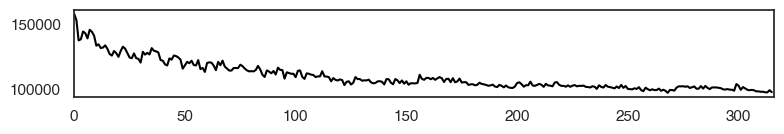

In [49]:
Disordered_circuits_burden = np.sum(Disordered_circuits,axis=0)

plt.figure(figsize=(8,1.5), facecolor='white')

ax = plt.gca()
ax.set_facecolor('white')

ax.plot(
    Disordered_circuits_burden,
    color='black',
    linewidth=1.5
)

ax.set_xlim(0, 316)

plt.tight_layout()

# plt.savefig(
#     "Figures/Figure3b_2.svg",
#     dpi=600,
#     bbox_inches="tight",
#     facecolor="white"
# )

plt.show()

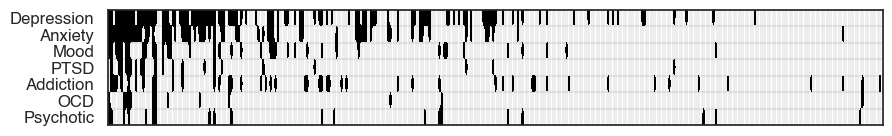

In [50]:
### plot mini data
cmap = matplotlib.colors.ListedColormap(['white', 'black'])

plt.rcParams["figure.figsize"] = (10,1.5)
plt.figure()
plt.imshow(mini_data_sorted,cmap = cmap, aspect='auto')
plt.rcParams["axes.grid"] = False 
ax = plt.gca();

# Major ticks
ax.set_xticks(np.arange(317))
ax.set_xticklabels([])

yticks = np.arange(len(mini_header)) 
ax.set_yticks(yticks)
ax.set_yticklabels(mini_header, fontsize=12)

# Minor ticks
ax.set_xticks(np.arange(-0.5, 317, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(mini_header), 1), minor=True)

# Gridlines based on minor ticks
ax.grid(which='minor', color='black', linestyle='-', linewidth=.1)

# plt.savefig(
#     "Figures/Figure3b_3.svg",
#     dpi=600,
#     bbox_inches="tight",
#     facecolor="white"
# )

In [51]:
# Conduct stability analysis on disordered circuit vectors using split-half resampling
#
# These helper functions below mirror the process used above to construct disordered circuit vectors. They are used to
# re-estimate all parameters for each resample (symptom scaling, residual estimation and scaling), and are then applied
# to all subjects so their reconstructed vectors can be compared with the original full-sample reference vectors.

def scale_BSI(BSI_raw, train_mask, epsilon=0.01):

    BSI_raw = np.asarray(BSI_raw, dtype=float)
    train_mask = np.asarray(train_mask, dtype=bool)

    train = BSI_raw[train_mask, :]

    # Same ddof=0 behavior as scipy.stats.zscore default
    mu = np.nanmean(train, axis=0, keepdims=True)
    sd = np.nanstd(train, axis=0, ddof=0, keepdims=True)

    BSI_z = (BSI_raw - mu) / sd
    train_z = BSI_z[train_mask, :]

    col_min = np.nanmin(train_z, axis=0, keepdims=True)
    col_max = np.nanmax(train_z, axis=0, keepdims=True)

    col_norm = (BSI_z - col_min) / (col_max - col_min)
    col_norm = col_norm * (1 - 2 * epsilon) + epsilon

    return 1 + col_norm * 9


def residuals_and_scale(E, y, train_mask, invert=False, epsilon=0.01):

    E = np.asarray(E, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    train_mask = np.asarray(train_mask, dtype=bool)

    valid = ~np.isnan(y)
    valid_indices = np.flatnonzero(valid)
    train_indices = np.flatnonzero(train_mask & valid)

    if E.shape[0] == 0 or train_indices.size < 3:
        return np.empty((E.shape[0], 0), dtype=float), np.array([], dtype=int)

    # ---- exact regression route used by edgewise_residuals_from_y ----
    y_train = y[train_indices]
    X_train = np.column_stack((np.ones_like(y_train), y_train))

    beta, _, _, _ = np.linalg.lstsq(
        X_train,
        E[:, train_indices].T,
        rcond=None
    )

    y_valid = y[valid_indices]
    X_valid = np.column_stack((np.ones_like(y_valid), y_valid))

    E_hat = (X_valid @ beta).T
    E_res = E[:, valid_indices] - E_hat

    if invert:
        E_res = E_res * -1

    # Locations of training subjects within the valid-subject matrix
    train_locations = np.searchsorted(valid_indices, train_indices)
    E_res_train = E_res[:, train_locations]

    # ---- same zscore route as the original code (ddof=0) ----
    resid_mean = np.nanmean(E_res_train, axis=1, keepdims=True)
    resid_sd = np.nanstd(E_res_train, axis=1, ddof=0, keepdims=True)
    E_res_z = (E_res - resid_mean) / resid_sd

    # ---- same rowwise min-max route as the original code ----
    E_res_z_train = E_res_z[:, train_locations]
    row_min = np.nanmin(E_res_z_train, axis=1, keepdims=True)
    row_max = np.nanmax(E_res_z_train, axis=1, keepdims=True)

    row_norm = (E_res_z - row_min) / (row_max - row_min)
    row_norm = row_norm * (1 - 2 * epsilon) + epsilon
    row_scaled = 1 + row_norm * 9

    return row_scaled, valid_indices


def edgewise_zscore(X, train_mask):

    X = np.asarray(X, dtype=float)
    train = X[:, train_mask]

    mu = np.nanmean(train, axis=1, keepdims=True)
    sd = np.nanstd(train, axis=1, ddof=0, keepdims=True)

    return (X - mu) / sd


def columnwise_pearson(X, Y):

    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y, dtype=np.float64)

    if X.shape != Y.shape:
        raise ValueError("X and Y must have identical shapes.")

    X_centered = X - np.nanmean(X, axis=0, keepdims=True)
    Y_centered = Y - np.nanmean(Y, axis=0, keepdims=True)

    numerator = np.nansum(X_centered * Y_centered, axis=0)
    denominator = np.sqrt(
        np.nansum(X_centered ** 2, axis=0)
        * np.nansum(Y_centered ** 2, axis=0)
    )

    correlations = np.full(X.shape[1], np.nan)
    valid = denominator > np.finfo(float).eps
    correlations[valid] = numerator[valid] / denominator[valid]

    return correlations


In [52]:
# Precompute masks/index mappings for the stability analysis.
vectors_resamp = np.asarray(vectors, dtype=float)
BSI_raw_resamp = np.asarray(BSI_raw_sig, dtype=float)

keep_rows = ~np.all(np.isnan(BSI_raw_resamp), axis=1)

BSI_raw_resamp = BSI_raw_resamp[keep_rows, :]
vectors_resamp = vectors_resamp[:, keep_rows]

n_edges, n_subjects = vectors_resamp.shape
n_measures = BSI_networks_sig.shape[1]

if n_measures != 24:
    print(f"Warning: found {n_measures} measures rather than 24.")

Sum_BSI_nets_resamp = np.nansum(BSI_networks_sig, axis=1)
active_mask = Sum_BSI_nets_resamp != 0
active_edge_indices = np.flatnonzero(active_mask)
n_active_edges = active_edge_indices.size

full_to_active = np.full(n_edges, -1, dtype=int)
full_to_active[active_edge_indices] = np.arange(n_active_edges)

measure_information = []

for m in range(n_measures):
    pos_mask = BSI_networks_sig_pos[:, m] != 0
    neg_mask = BSI_networks_sig_neg[:, m] != 0

    pos_full = np.flatnonzero(pos_mask)
    neg_full = np.flatnonzero(neg_mask)

    measure_information.append({
        "y": BSI_raw_resamp[:, m],
        "network_active": np.asarray(BSI_networks_sig[active_mask, m], dtype=float),
        "pos_full": pos_full,
        "neg_full": neg_full,
        "pos_active": full_to_active[pos_full],
        "neg_active": full_to_active[neg_full]
    })


In [53]:
def construct_weighted_circuits(train_mask, test_mask):
    """
    Cross-fitted reconstruction of disordered circuits.

    All regression and scaling parameters are estimated only from train_mask.

    The final returned circuit vectors contain ONLY subjects in test_mask.

    Training-subject circuit values are constructed internally only because
    they are required to estimate the final edgewise z-score/shift parameters.
    They are never used for stability evaluation.
    """
    train_mask = np.asarray(train_mask, dtype=bool)
    test_mask = np.asarray(test_mask, dtype=bool)

    if train_mask.shape != (n_subjects,):
        raise ValueError("train_mask has the wrong shape.")

    if test_mask.shape != (n_subjects,):
        raise ValueError("test_mask has the wrong shape.")

    if np.any(train_mask & test_mask):
        raise ValueError("train_mask and test_mask overlap.")

    train_indices = np.flatnonzero(train_mask)
    test_indices = np.flatnonzero(test_mask)

    # symptom scaling
    
    normData_this = scale_BSI(
        BSI_raw_resamp,
        train_mask=train_mask,
        epsilon=0.01
    )

    # Get residuals
    disorder_info = []

    for m, info in enumerate(measure_information):

        y = info["y"]

        pos_scaled, pos_valid = residuals_and_scale(
            E=vectors_resamp[info["pos_full"], :],
            y=y,
            train_mask=train_mask,
            invert=False,
            epsilon=0.01
        )

        neg_scaled, neg_valid = residuals_and_scale(
            E=vectors_resamp[info["neg_full"], :],
            y=y,
            train_mask=train_mask,
            invert=True,
            epsilon=0.01
        )

        disorder_info.append({
            "pos_active": info["pos_active"],
            "pos_scaled": pos_scaled,
            "pos_valid": pos_valid,
            "neg_active": info["neg_active"],
            "neg_scaled": neg_scaled,
            "neg_valid": neg_valid
        })

    # 
    # construct disordered circuits

    needed_indices = np.concatenate([
        train_indices,
        test_indices
    ])

    Weighted_CPMnets_vecs_this = np.empty(
        (n_active_edges, needed_indices.size),
        dtype=float
    )

    for col, n in enumerate(needed_indices):

        Weighted_vecs_temp = np.empty(
            (n_active_edges, n_measures),
            dtype=float
        )

        for m, info in enumerate(measure_information):

            w1 = np.zeros(
                n_active_edges,
                dtype=float
            )

            d = disorder_info[m]

            # Positive network

            if d["pos_valid"].size:

                j = np.searchsorted(
                    d["pos_valid"],
                    n
                )

                if (
                    j < d["pos_valid"].size
                    and d["pos_valid"][j] == n
                ):
                    w1[d["pos_active"]] = (
                        d["pos_scaled"][:, j]
                    )

            # Negative network

            if d["neg_valid"].size:

                j = np.searchsorted(
                    d["neg_valid"],
                    n
                )

                if (
                    j < d["neg_valid"].size
                    and d["neg_valid"][j] == n
                ):
                    w1[d["neg_active"]] = (
                        d["neg_scaled"][:, j]
                    )

            w2 = normData_this[n, m]

            Weighted_vecs_temp[:, m] = (
                info["network_active"]
                * (w1 + w2)
            )

        Weighted_CPMnets_vecs_this[:, col] = (
            np.nansum(
                Weighted_vecs_temp,
                axis=1
            )
        )

    # normalize edges
    
    # Estimate final mean/SD ONLY from the training half.
    # Then apply them to the held-out half.

    n_train = train_indices.size

    weighted_train = (
        Weighted_CPMnets_vecs_this[:, :n_train]
    )

    weighted_test = (
        Weighted_CPMnets_vecs_this[:, n_train:]
    )

    # Training-set edgewise mean / SD
    edge_mu = np.nanmean(
        weighted_train,
        axis=1,
        keepdims=True
    )

    edge_sd = np.nanstd(
        weighted_train,
        axis=1,
        ddof=0,
        keepdims=True
    )

    # z-score training data only to determine the same shift
    weighted_train_z = (
        weighted_train - edge_mu
    ) / edge_sd

    # Apply TRAINING normalization to HELD-OUT subjects
    weighted_test_z = (
        weighted_test - edge_mu
    ) / edge_sd

    # Same positive shift used in original pipeline,
    # estimated ONLY from training subjects
    circuit_min = np.nanmin(
        weighted_train_z
    )

    weighted_test_norm = (
        weighted_test_z
        + (-circuit_min)
    )

    return weighted_test_norm, test_indices

In [54]:
# Canonical full-sample disordered circuits
reference_vectors = Weighted_CPMnets_noZeros_norm.copy()

In [55]:
def run_one_stability_resample(seed):
    """
    Randomly split the sample into two halves and perform two-way
    cross-fitted circuit reconstruction.

    Fold 1:
        fit Half A -> reconstruct Half B

    Fold 2:
        fit Half B -> reconstruct Half A

    Thus every subject's reconstructed circuit is generated using
    parameters estimated WITHOUT that subject.
    """
    rng = np.random.default_rng(seed)

    # Random permutation of all subjects
    shuffled_indices = rng.permutation(n_subjects)

    split_point = n_subjects // 2

    half_A = shuffled_indices[:split_point]
    half_B = shuffled_indices[split_point:]

    mask_A = np.zeros(
        n_subjects,
        dtype=bool
    )
    mask_A[half_A] = True

    mask_B = np.zeros(
        n_subjects,
        dtype=bool
    )
    mask_B[half_B] = True

    # Storage for every subject
    similarities = np.full(
        n_subjects,
        np.nan,
        dtype=float
    )

    # A -> B

    circuits_B, indices_B = (
        construct_weighted_circuits(
            train_mask=mask_A,
            test_mask=mask_B
        )
    )

    similarities[indices_B] = (
        columnwise_pearson(
            circuits_B,
            reference_vectors[:, indices_B]
        )
    )

    # B -> A

    circuits_A, indices_A = (
        construct_weighted_circuits(
            train_mask=mask_B,
            test_mask=mask_A
        )
    )

    similarities[indices_A] = (
        columnwise_pearson(
            circuits_A,
            reference_vectors[:, indices_A]
        )
    )

    return similarities

In [56]:
n_resamples = 1000
random_seed = 42

rng = np.random.default_rng(random_seed)

seeds = rng.integers(
    low=0,
    high=np.iinfo(np.int32).max,
    size=n_resamples
)

stability_correlations = np.full(
    (n_resamples, n_subjects),
    np.nan,
    dtype=np.float32
)

for perm, seed in enumerate(seeds):

    stability_correlations[perm, :] = (
        run_one_stability_resample(
            seed=int(seed)
        )
    )

    if (perm + 1) % 25 == 0:
        print(
            f"Completed {perm + 1} "
            f"of {n_resamples} resamples"
        )

print(
    "Stability matrix shape:",
    stability_correlations.shape
)

KeyboardInterrupt: 

In [57]:
subject_stability = pd.DataFrame({
    "Subject": np.arange(n_subjects),
    "Mean_r": np.nanmean(stability_correlations, axis=0),
    "Median_r": np.nanmedian(stability_correlations, axis=0),
    "Q25_r": np.nanpercentile(stability_correlations, 25, axis=0),
    "Q75_r": np.nanpercentile(stability_correlations, 75, axis=0),
    "Minimum_r": np.nanmin(stability_correlations, axis=0),
    "SD_r": np.nanstd(stability_correlations, axis=0),
    "N_valid": np.sum(np.isfinite(stability_correlations), axis=0)
})

subject_stability["IQR_r"] = (
    subject_stability["Q25_r"].round(3).astype(str)
    + " - "
    + subject_stability["Q75_r"].round(3).astype(str)
)

subject_stability.to_csv(
    "Split_half_disordered_circuit_stability_by_subject.csv",
    index=False
)

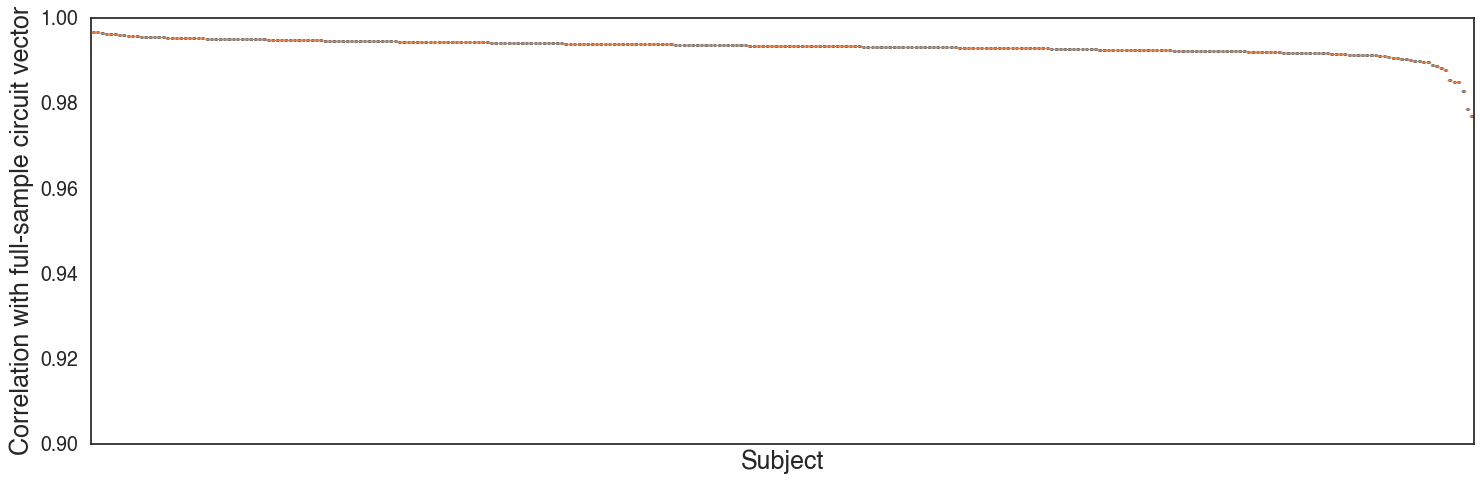

In [58]:
median_stability = np.nanmedian(
    stability_correlations,
    axis=0
)

sort_idx = np.argsort(median_stability)[::-1]

plot_data = [
    stability_correlations[:, subj][
        np.isfinite(stability_correlations[:, subj])
    ]
    for subj in sort_idx
]

fig, ax = plt.subplots(
    figsize=(15, 5),
    facecolor="white"
)

ax.boxplot(
    plot_data,
    showfliers=False,
    widths=0.7
)

ax.set_xlabel("Subject", fontsize=18)
ax.set_ylabel(
    "Correlation with full-sample circuit vector", fontsize=18
)
ax.tick_params(axis='y', labelsize=14)
ax.set_ylim(0.9, 1)
ax.set_xticks([])

plt.tight_layout()

plt.savefig(
    "Figures/Supplemental_Figure5.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Identify diagnoses related to edges in disordered circuit models

In [59]:
# Convert diagnosis matrix to dataframe
X_df = pd.DataFrame(
    mini_data_sorted.T,
    columns=mini_header
)

# Add intercept
X_df = sm.add_constant(X_df)

print(X_df.head())

   const  Depression  Anxiety  Mood  PTSD  Addiction  OCD  Psychotic
0    1.0           1        1     1     0          0    1          1
1    1.0           1        1     1     1          1    0          1
2    1.0           0        1     0     0          1    0          0
3    1.0           1        1     1     0          1    0          0
4    1.0           1        1     1     1          0    0          0


In [60]:
betas = []
pvals = []

for e in range(Disordered_circuits.shape[0]):

    model = sm.OLS(
        Disordered_circuits[e, :],
        X_df
    ).fit()

    betas.append(model.params)
    pvals.append(model.pvalues)

betas = pd.DataFrame(betas)
pvals = pd.DataFrame(pvals)

In [135]:
# Run the OLS model on unsorted edges disordered circuits to make it easier to re-sort them back into matrices
betas_unsorted = []
pvals_unsorted = []

for e in range(Weighted_CPMnets_norm_sorted.shape[0]):

    model = sm.OLS(
        Weighted_CPMnets_norm_sorted[e, :],
        X_df
    ).fit()

    betas_unsorted.append(model.params)
    pvals_unsorted.append(model.pvalues)

betas_unsorted = pd.DataFrame(betas_unsorted)
pvals_unsorted = pd.DataFrame(pvals_unsorted)

In [136]:
# Run the OLS model on models that were only weighted by symptoms and not edge residuals 
betas_control = []
pvals_control = []

# MINI diagnoses cannot be sorted
X_unsorted_df = pd.DataFrame(
    mini_data_transposed.T,
    columns=mini_header
)

# Add intercept
X_unsorted_df = sm.add_constant(X_unsorted_df)

print(X_unsorted_df.head())

for e in range(Weighted_CPMnets_noZeros_norm_control.shape[0]):

    model = sm.OLS(
        Weighted_CPMnets_noZeros_norm_control[e, :],
        X_unsorted_df
    ).fit()

    betas_control.append(model.params)
    pvals_control.append(model.pvalues)

betas_control = pd.DataFrame(betas_control)
pvals_control = pd.DataFrame(pvals_control)

   const  Depression  Anxiety  Mood  PTSD  Addiction  OCD  Psychotic
0    1.0           1        0     0     0          0    0          0
1    1.0           1        1     0     0          0    0          1
2    1.0           0        0     0     0          0    0          0
3    1.0           0        0     0     0          0    0          0
4    1.0           0        0     0     0          0    0          0


In [137]:
# Run the OLS model on JUST symptom data to test if disordered circuits are more specific to dxs than symptoms
betas_symp = []
pvals_symp = []

for e in range(normData_sorted.shape[0]):

    model = sm.OLS(
        normData_sorted[e, :],
        X_df
    ).fit()

    betas_symp.append(model.params)
    pvals_symp.append(model.pvalues)

betas_symp = pd.DataFrame(betas_symp)
pvals_symp = pd.DataFrame(pvals_symp)

In [138]:
alpha = 0.05

qvals = pd.DataFrame(
    np.nan,
    index=betas.index,
    columns=betas.columns
)

for dx in mini_header:
    p = pvals[dx].values
    valid = np.isfinite(p)

    qvals.loc[valid, dx] = multipletests(
        p[valid],
        method="fdr_bh"
    )[1]

sig_pos = (qvals[mini_header] < alpha) & (betas[mini_header] > 0)
sig_neg = (qvals[mini_header] < alpha) & (betas[mini_header] < 0)

sig_any = sig_pos | sig_neg

n_dx_per_circuit = sig_pos.sum(axis=1)

specific_circuits = {}
shared_circuits = np.where(n_dx_per_circuit > 1)[0]

for dx in mini_header:
    specific_circuits[dx] = np.where(
        sig_any[dx] & (n_dx_per_circuit == 1)
    )[0]

specific_counts = {
    dx: len(specific_circuits[dx])
    for dx in mini_header
}

shared_count = len(shared_circuits)

print(specific_counts)
print("Shared:", shared_count)

{'Depression': 110, 'Anxiety': 1796, 'Mood': 865, 'PTSD': 1297, 'Addiction': 0, 'OCD': 234, 'Psychotic': 0}
Shared: 13204


In [139]:
# Relate edges in control model to diagnoses
qvals_control = pd.DataFrame(
    np.nan,
    index=betas_control.index,
    columns=betas_control.columns
)

for dx in mini_header:
    p = pvals_control[dx].values
    valid = np.isfinite(p)

    qvals_control.loc[valid, dx] = multipletests(
        p[valid],
        method="fdr_bh"
    )[1]

sig_pos_control = (qvals_control[mini_header] < alpha) & (betas_control[mini_header] > 0)
sig_neg_control = (qvals_control[mini_header] < alpha) & (betas_control[mini_header] < 0)

sig_any_control = sig_pos_control | sig_neg_control

n_dx_per_circuit_control = sig_pos_control.sum(axis=1)

specific_circuits_control = {}
shared_circuits_control = np.where(n_dx_per_circuit_control > 1)[0]

for dx in mini_header:
    specific_circuits_control[dx] = np.where(
        sig_any_control[dx] & (n_dx_per_circuit_control == 1)
    )[0]

specific_counts_control = {
    dx: len(specific_circuits_control[dx])
    for dx in mini_header
}

shared_count_control = len(shared_circuits_control)

print(specific_counts_control)
print("Shared:", shared_count_control)

{'Depression': 0, 'Anxiety': 431, 'Mood': 0, 'PTSD': 0, 'Addiction': 0, 'OCD': 0, 'Psychotic': 0}
Shared: 18199


In [140]:
# Test specificity of diagnoses to symptoms

qvals_symp = pd.DataFrame(
    np.nan,
    index=betas_symp.index,
    columns=betas_symp.columns
)

for dx in mini_header:
    p = pvals_symp[dx].values
    valid = np.isfinite(p)

    qvals_symp.loc[valid, dx] = multipletests(
        p[valid],
        method="fdr_bh"
    )[1]

sig_pos_symp = (qvals_symp[mini_header] < alpha) & (betas_symp[mini_header] > 0)
sig_neg_symp = (qvals_symp[mini_header] < alpha) & (betas_symp[mini_header] < 0)

sig_any_symp = sig_pos_symp | sig_neg_symp

n_dx_per_symp = sig_pos_symp.sum(axis=1)

specific_symps = {}
shared_symps = np.where(n_dx_per_symp > 1)[0]

for dx in mini_header:
    specific_symps[dx] = np.where(
        sig_any_symp[dx] & (n_dx_per_symp == 1)
    )[0]

specific_counts_symp = {
    dx: len(specific_symps[dx])
    for dx in mini_header
}

shared_count = len(shared_symps)

print(specific_counts_symp)
print("Shared:", shared_count)

{'Depression': 0, 'Anxiety': 0, 'Mood': 0, 'PTSD': 0, 'Addiction': 0, 'OCD': 0, 'Psychotic': 0}
Shared: 20


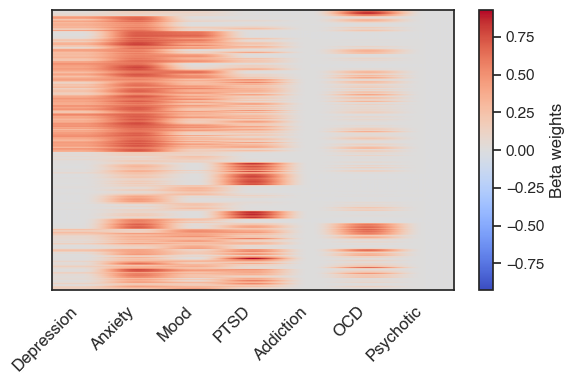

In [180]:
# Plot beta coefficients of circuits significantly related to diagnoses (Fig 4a)
effect_mat = betas[mini_header].copy()
effect_mat[~sig_pos] = 0

plt.figure(figsize=(6, 4), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

im = ax.imshow(
    effect_mat,
    aspect="auto",
    cmap="coolwarm",
    vmin=-np.nanpercentile(np.abs(effect_mat.values), 99),
    vmax=np.nanpercentile(np.abs(effect_mat.values), 99)
)

ax.set_xticks(np.arange(len(mini_header)))
ax.set_xticklabels(
    mini_header,
    rotation=45,
    ha='right',
    fontsize=12,  
    fontname='Helvetica'
)


ax.set_yticks([])
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Beta weights")

plt.tight_layout()

plt.savefig(
    "Figures/Figure4a.pdf",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

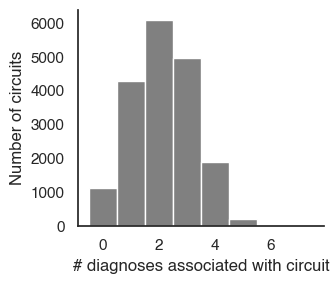

In [148]:
# Plot histogram of number of diagnoses associated with an edge
plt.figure(figsize=(3.5, 3), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

ax.hist(
    n_dx_per_circuit,
    bins=np.arange(0, len(mini_header) + 2) - 0.5,
    color="grey",
    edgecolor="white"
)

ax.set_xlabel("# diagnoses associated with circuit")
ax.set_ylabel("Number of circuits")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "Figures/Figure4b.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

/var/folders/fr/tfcrh98d0x107gyvfnssn9wc0000gn/T/ipykernel_13455/3429483221.py:169: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


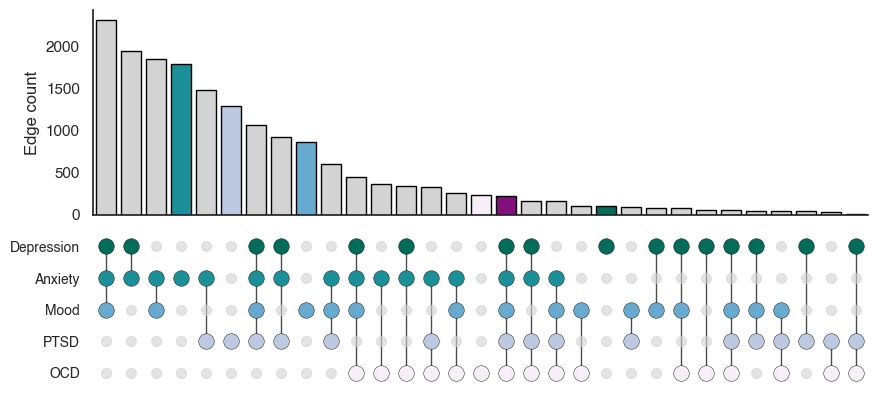

In [150]:
# Plot the overlap of diagnosis specific edges (fig 4c)
diagnoses = [
    "Depression",
    "Anxiety",
    "Mood",
    "PTSD",
    "OCD"
]

# Keep only these columns
sig_bool_pos = (
    sig_pos[diagnoses]
    .copy()
    .astype(bool)
)

# Remove circuits not significant for any of the selected diagnoses
sig_bool_pos = sig_bool_pos.loc[
    sig_bool_pos.any(axis=1)
]

sig_bool = sig_pos[mini_header].copy().astype(bool)

# remove circuits not significant for any diagnosis
sig_bool_pos = sig_bool.loc[sig_bool.any(axis=1)]

diagnoses = diagnoses[::-1]

sig_bool_pos = sig_bool_pos[diagnoses]

# Count intersections
intersection_counts = (
    sig_bool_pos
    .groupby(diagnoses)
    .size()
    .reset_index(name="count")
)

# Sort by intersection size
intersection_counts = intersection_counts.sort_values(
    "count",
    ascending=False
).reset_index(drop=True)

# keep only top N intersections
top_n = 40
intersection_counts = intersection_counts.iloc[:top_n, :]


dx_colors = {
    "Depression": "#016c59",
    "Anxiety": "#1c9099",
    "Mood": "#67a9cf",
    "PTSD": "#bdc9e1",
    "OCD": "#f6eff7",
}

# Plot
fig = plt.figure(figsize=(10, 5), facecolor="white")

gs = fig.add_gridspec(
    2, 1,
    height_ratios=[1.2, 1],
    hspace=0.05
)

ax_bar = fig.add_subplot(gs[0])
ax_mat = fig.add_subplot(gs[1], sharex=ax_bar)

x = np.arange(len(intersection_counts))


bar_colors = ["#d3d3d3"] * len(intersection_counts)  # Make bars light grey

# Bars to highlight (0-based indexing)
highlight_idx = [3, 5, 8, 15, 16, 20]

# Corresponding colors
highlight_colors = [
    "#1c9099",  # Anxiety
    "#bdc9e1",  # PTSD
    "#67a9cf",  # Mood
    "#f6eff7",  # OCD    
    "#810f7c",  # All
    "#016c59"  # Depression
]


for idx, color in zip(highlight_idx, highlight_colors):
    if idx < len(bar_colors):
        bar_colors[idx] = color

# Plot
ax_bar.bar(
    x,
    intersection_counts["count"],
    color=bar_colors,
    edgecolor="black"
)


ax_bar.set_ylabel("Edge count")
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)

# Dot matrix
for row, dx in enumerate(diagnoses):

    active = intersection_counts[dx].values.astype(bool)

    # inactive dots
    ax_mat.scatter(
        x,
        np.full_like(x, row),
        s=50,
        color="lightgray",
        alpha=0.6
    )

    # active colored dots
    ax_mat.scatter(
        x[active],
        np.full(np.sum(active), row),
        s=125,
        color=dx_colors[dx],
        edgecolor="black",
        linewidth=0.3
    )

# Connecting vertical lines for active sets
for col in range(len(intersection_counts)):

    active_rows = np.where(
        intersection_counts.loc[col, diagnoses].values.astype(bool)
    )[0]

    if len(active_rows) > 1:
        ax_mat.plot(
            [col, col],
            [active_rows.min(), active_rows.max()],
            color="black",
            linewidth=1,
            alpha=0.7,
            zorder=0
        )

ax_mat.set_yticks(np.arange(len(diagnoses)))
ax_mat.set_yticklabels(
    diagnoses,
    fontsize=10,
    fontweight="bold",
    fontname="Helvetica"
)

ax_mat.set_xlim(-0.5, len(intersection_counts) - 0.5)

ax_mat.spines["top"].set_visible(False)
ax_mat.spines["right"].set_visible(False)
ax_mat.spines["left"].set_visible(False)
ax_mat.spines["bottom"].set_visible(False)

ax_mat.tick_params(axis="x", bottom=False, labelbottom=False)
ax_mat.tick_params(axis="y", left=False)

ax_mat.set_ylim(-0.7, len(diagnoses) - 0.3)

plt.tight_layout()

plt.savefig(
    "Figures/Figure4c.pdf",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Display network localizations of edges specific to diagnoses and shared between all  

In [151]:
# Get p-values from unsorted disordered circuit vectors

qvals_unsorted = pd.DataFrame(
    np.nan,
    index=betas_unsorted.index,
    columns=betas_unsorted.columns
)

for dx in mini_header:
    p = pvals_unsorted[dx].values
    valid = np.isfinite(p)

    qvals_unsorted.loc[valid, dx] = multipletests(
        p[valid],
        method="fdr_bh"
    )[1]

sig_pos_unsorted = (qvals_unsorted[mini_header] < alpha) & (betas_unsorted[mini_header] > 0)
sig_neg_unsorted = (qvals_unsorted[mini_header] < alpha) & (betas_unsorted[mini_header] < 0)

sig_any_unsorted = sig_pos_unsorted | sig_neg_unsorted

n_dx_per_circuit_unsorted = sig_pos_unsorted.sum(axis=1)

specific_circuits_unsorted = {}
shared_circuits_unsorted = np.where(n_dx_per_circuit > 1)[0]

for dx in mini_header:
    specific_circuits_unsorted[dx] = np.where(
        sig_any_unsorted[dx] & (n_dx_per_circuit_unsorted == 1)
    )[0]

specific_counts_unsorted = {
    dx: len(specific_circuits_unsorted[dx])
    for dx in mini_header
}

shared_count_unsorted = len(shared_circuits_unsorted)

print(specific_counts_unsorted)
print("Shared:", shared_count_unsorted)

{'Depression': 110, 'Anxiety': 1796, 'Mood': 865, 'PTSD': 1297, 'Addiction': 0, 'OCD': 234, 'Psychotic': 0}
Shared: 13204


In [152]:
effect_mat_unsorted = betas_unsorted[mini_header].copy()
effect_mat_unsorted[~sig_pos_unsorted] = 0

effect_mat_unsorted = effect_mat_unsorted.iloc[
    :,
    ~effect_mat_unsorted.columns.isin(
        effect_mat_unsorted.columns[[4, 6]]
    )
]

E = np.asarray(effect_mat_unsorted)

# Treat nonzero finite values as "present"
present = np.isfinite(E) & (E != 0)

# New matrix: 35778 x 6
specific_shared_mat = np.zeros((E.shape[0], 6), dtype=int)

# Columns 1-5: diagnosis-specific rows
# specific to col c = present in c AND absent from all other columns
for c in range(5):
    specific_shared_mat[:, c] = (
        present[:, c] & (present.sum(axis=1) == 1)
    ).astype(int)

# Column 6: present in all 5 columns
specific_shared_mat[:, 5] = (
    present.sum(axis=1) == 5
).astype(int)


# Reshape into 268x268 symmetrical matrices
n_nodes = 268
iu = np.triu_indices(n_nodes, k=1)

mats_6 = []

for c in range(specific_shared_mat.shape[1]):

    mat = np.zeros((n_nodes, n_nodes))

    # fill upper triangle
    mat[iu] = specific_shared_mat[:, c]

    # mirror to lower triangle
    mat = mat + mat.T

    mats_6.append(mat)

# mats_6 is a list of 6 symmetric 268 x 268 matrices
print(len(mats_6))
print(mats_6[0].shape)

6
(268, 268)


In [153]:
mats_6_sorted = [
    mat[np.ix_(sorted_net_ixs, sorted_net_ixs)]
    for mat in mats_6
]

# Find where each network block ends
boundaries = []
current_net = sorted_network_assignments[0]
for i in range(1, len(sorted_network_assignments)):
    if sorted_network_assignments[i] != current_net:
        boundaries.append(i)
        current_net = sorted_network_assignments[i]
        
# Compute tick positions for network labels
tick_positions = []
last_ix = 0
for net in range(len(network_names)):
    count = np.sum(sorted_network_assignments == net)
    tick_positions.append(last_ix + count // 2)
    last_ix += count
        
# Compute tick positions for network labels
tick_positions = []
last_ix = 0
for net in range(len(network_names)):
    count = np.sum(sorted_network_assignments == net)
    tick_positions.append(last_ix + count // 2)
    last_ix += count
    
mats_6_sorted = np.stack(mats_6_sorted, axis=2)

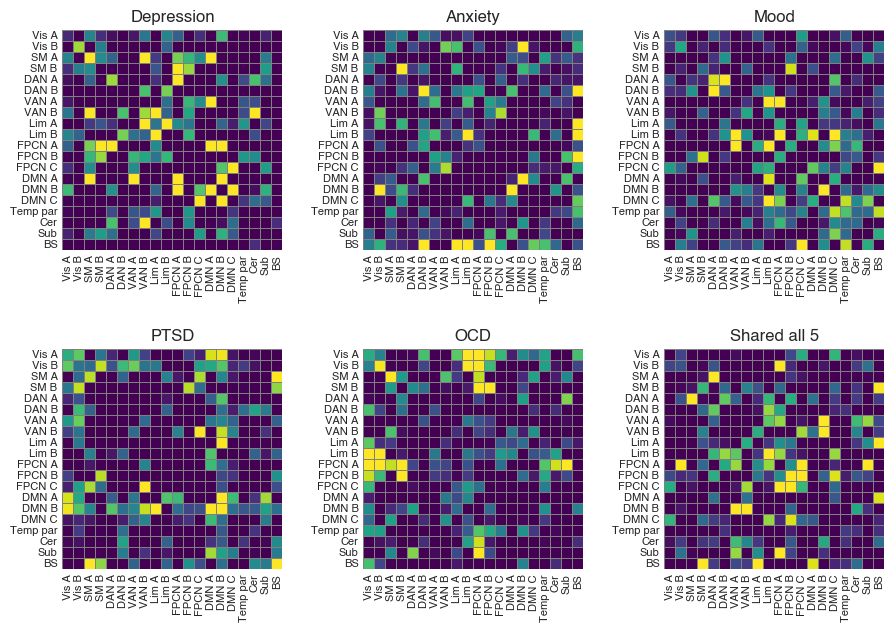

In [155]:
titles = [
    "Depression",
    "Anxiety",
    "Mood",
    "PTSD",
    "OCD",
    "Shared all 5"
]

netlabels = {}
for n in range(268):
    netlabels[n] = network_names[network_assignments[n]]

# Number of networks
n_networks = len(network_names)
mats_to_plot = [mats_6_sorted[:, :, i] for i in range(mats_6_sorted.shape[2])]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(11, 7),
    facecolor="white"
)

axes = axes.ravel()

for i, ax in enumerate(axes):

    mat = mats_to_plot[i]
    
    # Initialize reduced matrix
    reduced_mat = np.zeros((n_networks, n_networks))
    
    # Loop through each pair of networks
    for ind in range(n_networks):
        for j in range(n_networks):
            # Get indices for nodes in network i and network j
            idx_i = np.where(network_assignments == ind)[0]
            idx_j = np.where(network_assignments == j)[0]

            # # Extract submatrix and compute mean
            block_mean = np.mean(mat[np.ix_(idx_i, idx_j)])
            reduced_mat[ind, j] = reduced_mat[j, ind] = block_mean
            
    iu = np.triu_indices(n_networks)

    mu = np.mean(reduced_mat[iu])
    sigma = np.std(reduced_mat[iu])

    reduced_mat = (reduced_mat - mu) / sigma

    sns.heatmap(
        reduced_mat,
        ax=ax,
        vmin=0,
        vmax=2,
        cmap="viridis",
        xticklabels=network_names,
        yticklabels=network_names,
        square=True,
        cbar=False,          # one shared colorbar later
        linewidths=0.5,
        linecolor="gray"
    )

    ax.set_title(
        titles[i],
        fontsize=12,
        fontweight="bold",
        fontname="Helvetica"
    )

    ax.tick_params(
        axis="x",
        rotation=90,
        labelsize=8,
        length=0
    )

    ax.tick_params(
        axis="y",
        rotation=0,
        labelsize=8,
        length=0
    )
    
fig.subplots_adjust(hspace=.45)

plt.savefig(
    "Figures/Figure5.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

In [156]:
# Get the top 5 network-network pairs for each diagnosis
top_vals_all = []

for m, mat in enumerate(mats_to_plot):
    mat = np.asarray(mat)
    
    # Initialize reduced matrix
    reduced_mat = np.zeros((n_networks, n_networks))
    
    # Loop through each pair of networks
    for ind in range(n_networks):
        for j in range(n_networks):
            # Get indices for nodes in network i and network j
            idx_i = np.where(network_assignments == ind)[0]
            idx_j = np.where(network_assignments == j)[0]

            # # Extract submatrix and compute mean
            block_mean = np.mean(mat[np.ix_(idx_i, idx_j)])
            reduced_mat[ind, j] = reduced_mat[j, ind] = block_mean
            
            
    # Use upper triangle only so symmetric pairs aren't double-counted
    # k=1 excludes diagonal; use k=0 if you want diagonal included
    iu = np.triu_indices_from(reduced_mat, k=0)

    vals = reduced_mat[iu]

    # ignore NaNs if present
    valid = ~np.isnan(vals)
    vals_valid = vals[valid]
    rows_valid = iu[0][valid]
    cols_valid = iu[1][valid]

    top_idx = np.argsort(vals_valid)[-5:][::-1]

    for rank, idx in enumerate(top_idx, start=1):
        y_ind = rows_valid[idx]
        x_ind = cols_valid[idx]

        top_vals_all.append({
            "matrix": m,
            "rank": rank,
            "value": vals_valid[idx],
            "y_label": network_names[y_ind],
            "x_label": network_names[x_ind],
            "y_index": y_ind,
            "x_index": x_ind,
        })

top_vals_df = pd.DataFrame(top_vals_all)
top_vals_df

,matrix,rank,value,y_label,x_label,y_index,x_index
0,0,1,0.020833,FPCN A,DMN A,10,13
1,0,2,0.017857,DAN A,FPCN A,4,10
2,0,3,0.016667,DMN A,DMN B,13,14
3,0,4,0.016484,SM A,VAN B,2,7
4,0,5,0.013393,VAN B,Cer,7,17
5,1,1,0.142012,Lim B,Lim B,9,9
6,1,2,0.134615,Lim B,BS,9,19
7,1,3,0.125000,DAN B,BS,5,19
8,1,4,0.125000,DAN B,DAN B,5,5
9,1,5,0.111111,Lim A,BS,8,19


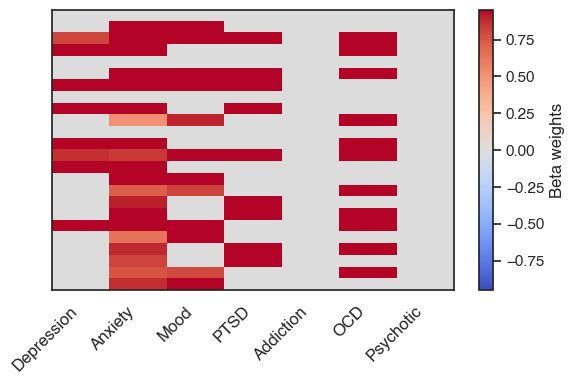

In [165]:
# Plot beta coefficients of symptoms related to diagnoses (supplemental fig 6)
effect_mat = betas_symp[mini_header].copy()
effect_mat[~sig_pos_symp] = 0

plt.figure(figsize=(6, 4), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

im = ax.imshow(
    effect_mat,
    aspect="auto",
    cmap="coolwarm",
    vmin=-0.95,
    vmax=0.95
)

ax.set_xticks(np.arange(len(mini_header)))
ax.set_xticklabels(
    mini_header,
    rotation=45,
    ha='right',
    fontsize=12,  
    fontname='Helvetica'
)


ax.set_yticks([])
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Beta weights")

plt.tight_layout()

plt.savefig(
    "Figures/Supplemental_Figure_6_1.pdf",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

/var/folders/fr/tfcrh98d0x107gyvfnssn9wc0000gn/T/ipykernel_13455/2090128543.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


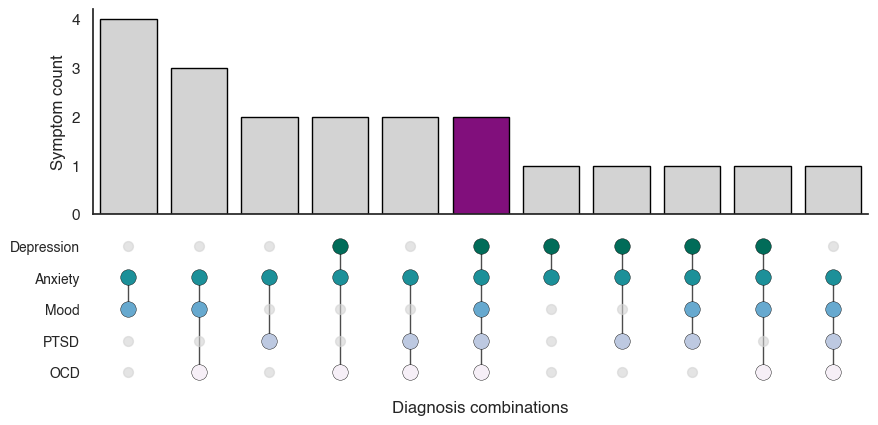

In [170]:
# Supplemental fig 6
diagnoses = [
    "Depression",
    "Anxiety",
    "Mood",
    "PTSD",
    "OCD"
]

# Keep only these columns
sig_bool_pos_symp = (
    sig_pos_symp[diagnoses]
    .copy()
    .astype(bool)
)

# Remove circuits not significant for any of the selected diagnoses
sig_bool_pos_symp = sig_bool_pos_symp.loc[
    sig_bool_pos_symp.any(axis=1)
]

sig_bool_symp = sig_pos_symp[mini_header].copy().astype(bool)

# remove circuits not significant for any diagnosis
sig_bool_pos_symp = sig_bool_symp.loc[sig_bool_symp.any(axis=1)]

diagnoses = diagnoses[::-1]

sig_bool_pos_symp = sig_bool_pos_symp[diagnoses]


intersection_counts_symp = (
    sig_bool_pos_symp
    .groupby(diagnoses)
    .size()
    .reset_index(name="count")
)

# Sort by intersection size
intersection_counts_symp = intersection_counts_symp.sort_values(
    "count",
    ascending=False
).reset_index(drop=True)

top_n = 40
intersection_counts_symp = intersection_counts_symp.iloc[:top_n, :]

dx_colors = {
    "Depression": "#016c59",
    "Anxiety": "#1c9099",
    "Mood": "#67a9cf",
    "PTSD": "#bdc9e1",
    "OCD": "#f6eff7",
}

# Plot
fig = plt.figure(figsize=(10, 5), facecolor="white")

gs = fig.add_gridspec(
    2, 1,
    height_ratios=[1.2, 1],
    hspace=0.05
)

ax_bar = fig.add_subplot(gs[0])
ax_mat = fig.add_subplot(gs[1], sharex=ax_bar)

x = np.arange(len(intersection_counts_symp))

# Default: light grey
bar_colors = ["#d3d3d3"] * len(intersection_counts_symp)

# Bars to highlight (0-based indexing)
highlight_idx = [5]

# Corresponding colors
highlight_colors = [
    "#810f7c",  # All
]

for idx, color in zip(highlight_idx, highlight_colors):
    if idx < len(bar_colors):
        bar_colors[idx] = color

# Plot
ax_bar.bar(
    x,
    intersection_counts_symp["count"],
    color=bar_colors,
    edgecolor="black"
)


ax_bar.set_ylabel("Symptom count")
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)

# Dot matrix
for row, dx in enumerate(diagnoses):

    active = intersection_counts_symp[dx].values.astype(bool)

    # inactive dots
    ax_mat.scatter(
        x,
        np.full_like(x, row),
        s=50,
        color="lightgray",
        alpha=0.6
    )

    # active colored dots
    ax_mat.scatter(
        x[active],
        np.full(np.sum(active), row),
        s=125,
        color=dx_colors[dx],
        edgecolor="black",
        linewidth=0.3
    )

# Connecting vertical lines for active sets
for col in range(len(intersection_counts_symp)):

    active_rows = np.where(
        intersection_counts_symp.loc[col, diagnoses].values.astype(bool)
    )[0]

    if len(active_rows) > 1:
        ax_mat.plot(
            [col, col],
            [active_rows.min(), active_rows.max()],
            color="black",
            linewidth=1,
            alpha=0.7,
            zorder=0
        )

ax_mat.set_yticks(np.arange(len(diagnoses)))
ax_mat.set_yticklabels(
    diagnoses,
    fontsize=10,
    fontweight="bold",
    fontname="Helvetica"
)

ax_mat.set_xlabel("Diagnosis combinations")
ax_mat.set_xlim(-0.5, len(intersection_counts_symp) - 0.5)

ax_mat.spines["top"].set_visible(False)
ax_mat.spines["right"].set_visible(False)
ax_mat.spines["left"].set_visible(False)
ax_mat.spines["bottom"].set_visible(False)

ax_mat.tick_params(axis="x", bottom=False, labelbottom=False)
ax_mat.tick_params(axis="y", left=False)

ax_mat.set_ylim(-0.7, len(diagnoses) - 0.3)


plt.tight_layout()

plt.savefig(
    "Figures/Supplemental_Figure_6_2.pdf",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

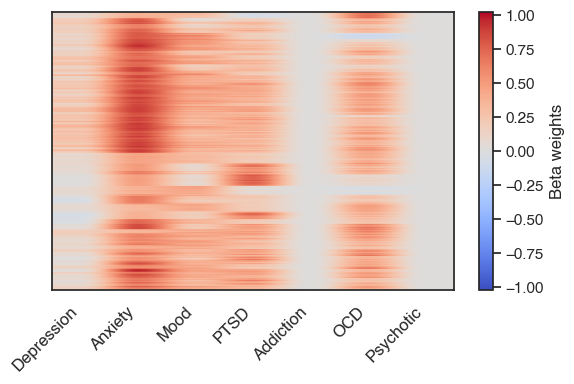

In [181]:
# Plot beta coefficients of unweighted disordered circuits related to diagnoses (supplemental fig 7) 
effect_mat = betas_control[mini_header].copy()

effect_mat_reordered = effect_mat.iloc[order_edges, :].to_numpy()

effect_mat_reordered[~sig_pos_control] = 0

plt.figure(figsize=(6, 4), facecolor="white")
ax = plt.gca()
ax.set_facecolor("white")

im = ax.imshow(
    effect_mat_reordered,
    aspect="auto",
    cmap="coolwarm",
    vmin=-np.nanpercentile(np.abs(effect_mat.values), 99),
    vmax=np.nanpercentile(np.abs(effect_mat.values), 99)
)

ax.set_xticks(np.arange(len(mini_header)))
ax.set_xticklabels(
    mini_header,
    rotation=45,
    ha='right',
    fontsize=12,  
    fontname='Helvetica'
)


ax.set_yticks([])
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Beta weights")

plt.tight_layout()

plt.savefig(
    "Figures/Supplemental_Figure7_1.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

/var/folders/fr/tfcrh98d0x107gyvfnssn9wc0000gn/T/ipykernel_13455/213834608.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


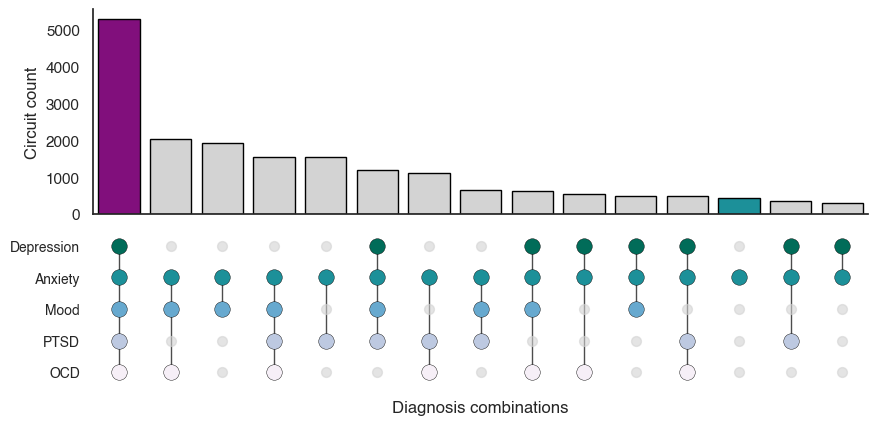

In [185]:
# Supplemental fig 7
diagnoses = [
    "Depression",
    "Anxiety",
    "Mood",
    "PTSD",
    "OCD"
]

# Keep only these columns
sig_bool_pos_control = (
    sig_pos_control[diagnoses]
    .copy()
    .astype(bool)
)

# Remove circuits not significant for any of the selected diagnoses
sig_bool_pos_control = sig_bool_pos_control.loc[
    sig_bool_pos_control.any(axis=1)
]

sig_bool_control = sig_pos_control[mini_header].copy().astype(bool)

# remove circuits not significant for any diagnosis
sig_bool_pos_control = sig_bool_control.loc[sig_bool_control.any(axis=1)]

diagnoses = diagnoses[::-1]

sig_bool_pos_control = sig_bool_pos_control[diagnoses]

intersection_counts = (
    sig_bool_pos_control
    .groupby(diagnoses)
    .size()
    .reset_index(name="count")
)

# Sort by intersection size
intersection_counts = intersection_counts.sort_values(
    "count",
    ascending=False
).reset_index(drop=True)

top_n = 40
intersection_counts = intersection_counts.iloc[:top_n, :]


dx_colors = {
    "Depression": "#016c59",
    "Anxiety": "#1c9099",
    "Mood": "#67a9cf",
    "PTSD": "#bdc9e1",
    "OCD": "#f6eff7",
}

# Plot
fig = plt.figure(figsize=(10, 5), facecolor="white")

gs = fig.add_gridspec(
    2, 1,
    height_ratios=[1.2, 1],
    hspace=0.05
)

ax_bar = fig.add_subplot(gs[0])
ax_mat = fig.add_subplot(gs[1], sharex=ax_bar)

x = np.arange(len(intersection_counts))


# Default: light grey
bar_colors = ["#d3d3d3"] * len(intersection_counts)

# Bars to highlight 
highlight_idx = [0, 12]

highlight_colors = [
    "#810f7c",  # All
    "#1c9099",  # Anxiety
]


for idx, color in zip(highlight_idx, highlight_colors):
    if idx < len(bar_colors):
        bar_colors[idx] = color

# Plot
ax_bar.bar(
    x,
    intersection_counts["count"],
    color=bar_colors,
    edgecolor="black"
)


ax_bar.set_ylabel("Circuit count")
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)

# Dot matrix
for row, dx in enumerate(diagnoses):

    active = intersection_counts[dx].values.astype(bool)

    # inactive dots
    ax_mat.scatter(
        x,
        np.full_like(x, row),
        s=50,
        color="lightgray",
        alpha=0.6
    )

    # active colored dots
    ax_mat.scatter(
        x[active],
        np.full(np.sum(active), row),
        s=125,
        color=dx_colors[dx],
        edgecolor="black",
        linewidth=0.3
    )

# Connecting vertical lines for active sets
for col in range(len(intersection_counts)):

    active_rows = np.where(
        intersection_counts.loc[col, diagnoses].values.astype(bool)
    )[0]

    if len(active_rows) > 1:
        ax_mat.plot(
            [col, col],
            [active_rows.min(), active_rows.max()],
            color="black",
            linewidth=1,
            alpha=0.7,
            zorder=0
        )

ax_mat.set_yticks(np.arange(len(diagnoses)))
ax_mat.set_yticklabels(
    diagnoses,
    fontsize=10,
    fontweight="bold",
    fontname="Helvetica"
)

ax_mat.set_xlabel("Diagnosis combinations")
ax_mat.set_xlim(-0.5, len(intersection_counts) - 0.5)

ax_mat.spines["top"].set_visible(False)
ax_mat.spines["right"].set_visible(False)
ax_mat.spines["left"].set_visible(False)
ax_mat.spines["bottom"].set_visible(False)

ax_mat.tick_params(axis="x", bottom=False, labelbottom=False)
ax_mat.tick_params(axis="y", left=False)

ax_mat.set_ylim(-0.7, len(diagnoses) - 0.3)

plt.tight_layout()


plt.savefig(
    "Figures/Supplemental_Figure7_1.svg",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()